# CMU 11-768 Assignment 2 · Evaluating a data-visualization agent

*What we built, why we built it that way, and what we learned. November 2026.*

An LLM agent receives a request such as "draw a grouped bar chart of quarterly revenue by region from this CSV". It writes and runs Python in a sandbox and saves `figure.png`. This project is about the step after that: an automated **validator** that reads the request, the agent's trajectory and the saved figure, and reports which kinds of mistake the chart contains. It is an independent, non-credit reproduction of Assignment 2 of CMU 11-768 (*Agents*).

### The project in one minute

- **The problem.** A person can judge a chart quickly, but not thousands of them. The assignment's starter validator asks a vision model one yes/no question per error family. On 110 human-labelled runs it agrees with the labels only moderately (macro-MCC 0.52).
- **What we built.**
  1. A validator ([`validator/solution.py`](https://github.com/xqzr2000/cmu-11-768-assignment-2/blob/main/validator/solution.py)) that decides whether a usable figure exists from the file itself, then asks the judge model for a structured requirement checklist and a separate readability review.
  2. An agent runner ([`workflow/sandbox_generate.py`](https://github.com/xqzr2000/cmu-11-768-assignment-2/blob/main/workflow/sandbox_generate.py)) that drives three hosted LLM agents from three providers through one bash-tool loop. Their commands run in a fresh Docker container with no network, one per run. The container comes from the sandbox we wrote in Assignment 1.
  3. Five new evaluation tasks with answer keys, 15 labelled agent runs, and deterministic Harbor verifiers tested against deliberately broken "mutant" solutions.
- **What we measured.** Macro-MCC rose from 0.5235 to 0.8726 on the 110 seed runs. One later idea fixed every miss on our own tasks but lowered the seed score, so we measured it, switched it off and recorded why.
- **What it cost.** $4.84 of judge API calls for every number in the report, plus less than $1 of agent calls, within the $10 cap we set before starting.

| Result | Value |
| --- | --- |
| Seed macro-MCC, starter baseline → final | **0.5235 → 0.8726** |
| `execution_failure` MCC | 0.5945 → **1.0000**, with no model call |
| `wrong_data` false positives on the seed runs | 46 → **9** |
| New agent runs | 5 tasks × 3 agents = **15**, every one labelled |
| Harbor verifiers | 5/5 reference solutions score 1.0. The wrong-aggregation mutant is rejected. The unreadable-labels mutant is **accepted**, a verifier blind spot we built a test to show |

### What this project demonstrates

| Skill | Section |
| --- | --- |
| Designing and measuring an LLM-as-judge evaluator | §3, §4, §7 |
| Choosing a metric for rare, imbalanced labels (MCC) | §3 |
| Running untrusted model-written code safely | §5 |
| Putting three LLM providers behind one interface | §2, §5 |
| Writing test tasks with answer keys that target a known weakness | §6, §8 |
| Deciding from measurements, including turning a change back off | §7 |
| Tracking cost and model provenance | §9 |
| Knowing when to stop building infrastructure | §2 |

### How to read and run this notebook

The cell outputs are saved, so the notebook reads on GitHub as it is. To run it yourself, open it in Colab with a CPU runtime and run all cells. Sections 0 to 11 read committed files and make no model calls, so they need no API key. Section 12 is one optional live judge call with your own OpenAI key. Section 13 lists the Docker commands for a Codespace.

| § | Topic | Runs in this notebook |
| --- | --- | --- |
| 0 | Set up the source checkout | Clone at a pinned commit |
| 1 | The problem: what a validator sees | One seed run, its label and three verdicts |
| 2 | How the project unfolded | Git history, early pilots, provider probes |
| 3 | Part 1: diagnose the starter baseline | MCC by hand, the two error types |
| 4 | Part 2: two validator changes | File check on 110 runs, judge calls with a scripted judge, scores |
| 5 | The agent sandbox | The real agent loop with a scripted model, the 15 recorded runs |
| 6 | Part 3: tasks built to expose the validator | What the judge can see of a large CSV, the 15 figures |
| 7 | Part 4: iterate and measure | Four validator versions on both run sets |
| 8 | Harbor verifiers | A reference solution and two mutants |
| 9 | Models, cost and budget | Token usage and the judge-spend ledger |
| 10 | Lessons, limitations, next steps | Text |
| 11 | The repository's offline checks | Unit tests and the scorer CLI in a `uv` environment |
| 12 | Optional live judge call | Off by default |
| 13 | Docker lab in Codespaces | Commands only |

### Who did what

"We" in this notebook means Russell, the author, working with AI coding assistants. Russell made the model, budget and sandbox decisions, ran everything that needed API keys or Docker in his Codespace, and reviewed the labels and the report. An earlier AI assistant built the offline infrastructure in Sessions 001–014. Claude wrote most of the final validator, agent runner, tasks and report on the `finish-assignment` branch. [`AI_USAGE.md`](https://github.com/xqzr2000/cmu-11-768-assignment-2/blob/main/AI_USAGE.md) gives the exact split.

### An adaptation, not a course submission

The course requires Qwen3-VL-30B as the judge and three specific open-weight agents, all served on Modal. We used hosted APIs instead (§9 explains why), so every score here describes our setup and cannot be compared with course results.

## 0 · Set up the source checkout

The examples pin the source, seed artifacts and committed predictions to one commit, so the numbers below cannot drift. The notebook imports the validator, runner and scorer into this kernel. The repository's own tests run in §11 in a separate `uv` environment.

In [1]:
import importlib.util
import json
import os
import re
import shutil
import subprocess
import sys
from pathlib import Path

SOURCE_COMMIT = "5dd09f26306de20576bcb1ba5cda1940a5c712ca"
repo = Path.cwd() / "assignment2_source"

if not repo.exists():
    subprocess.run(
        ["git", "clone", "--quiet", "https://github.com/xqzr2000/cmu-11-768-assignment-2.git", str(repo)],
        check=True,
    )
subprocess.run(["git", "-C", str(repo), "checkout", "--quiet", "--detach", SOURCE_COMMIT], check=True)

needed = {"dotenv": "python-dotenv", "openai": "openai", "pydantic": "pydantic", "tqdm": "tqdm",
          "PIL": "pillow", "matplotlib": "matplotlib", "pandas": "pandas", "pytest": "pytest"}
missing = [package for module, package in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
if shutil.which("uv") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv"], check=True)
sys.path.insert(0, str(repo))

from validator.runner import runs

seed_runs = {run.run_id: run for run in runs()}
print(f"{len(seed_runs)} seed runs loaded from {repo.name}/artifacts")
assert len(seed_runs) == 110

110 seed runs loaded from assignment2_source/artifacts


## 1 · The problem: what a validator sees and must decide

For each run the validator gets exactly four things: the task instruction, the input files, the agent's trajectory (every message, command and command output) and the saved `figure.png`, if there is one. It never sees the human label or a reference image. It returns a list of errors. Each error has one of four families and one sentence of evidence.

| Family | Question it answers | Example |
| --- | --- | --- |
| `execution_failure` | Is there a usable figure at all? | No `figure.png`, or a truncated file |
| `wrong_data` | Are the right values plotted? | A category filtered out, units summed in place of revenue |
| `wrong_chart` | Is it drawn the way the request asked? | Stacked bars where grouped bars were asked for, a missing axis label |
| `hard_to_read` | Can a reader read what is drawn? | Clipped tick labels, a legend covering the data |

A run can have several errors, or none. The families sound distinct, but a judge model mixes them up easily. A missing axis label is a design error, not a data error. Overlapping labels are a readability error, not a design error, even when the instruction itself says "labels must not overlap". Much of this project is about keeping the four apart.

The assignment has four parts, and this notebook follows them.

| Part | The assignment asks | Our answer | Section |
| --- | --- | --- | --- |
| 1 | Score the starter baseline on 110 labelled seed runs and name two recurring error types | Execution judged from the trajectory's story; error families mixed up | §3 |
| 2 | Implement two validator improvements and score them | A file-based execution check; a requirement checklist plus a readability call | §4 |
| 3 | Write at least five tasks in two weakness classes, run three agents, label the runs, package Harbor verifiers with mutants | 5 tasks, 15 runs in our own sandbox, 5 Harbor packages, 2 mutants | §5, §6, §8 |
| 4 | Iterate on the validator and analyse the result | A `legibility` requirement kind kept; an overlay check measured and switched off | §7 |

### 1.1 · The run record

Each directory under `artifacts/` holds a `result.json` and, when the agent saved one, a `figure.png`. `Run.load` turns that into the object every validator receives: the task instructions, the chat messages of the trajectory, the figure path and any input files. `transcript` is the compact text version of the trajectory that `validator/solution.py` puts in the judge prompt. It keeps the agent's commands and clips long tool output.

Seed run `021` asks for a box plot. Read the instructions and the agent's script before looking at the labels in the next cell.

Using matplotlib, draw a vertical box plot comparing the distribution of request latency (in milliseconds) across four backend services. The samples are:
  auth:     82, 91, 95, 99, 104, 110, 118, 240
  catalog:  45, 52, 58, 61, 65, 70, 74, 80
  search:   130, 142, 150, 158, 165, 171, 180, 195
  checkout: 60, 66, 72, 77, 83, 90, 96, 300
Requirements:
1. One box per service, side by side along the x axis in the order given above, with the service name as that box's x tick label.
2. The median line of every box must sit at that service's median latency.
3. Keep matplotlib's default whisker rule (1.5 x IQR) and leave outliers showing as individual points -- do not clip, winsorise or drop them.
4. Give the chart a title and label both axes; the y axis is latency in milliseconds.

Input files: none | messages: 22
Measured from the PNG: pixel size 2400x1800; DPI metadata 300; implied figure size 8.00x6.00 inches

--- transcript (first 1,400 characters) ---
[assistant]
I will work step by ste

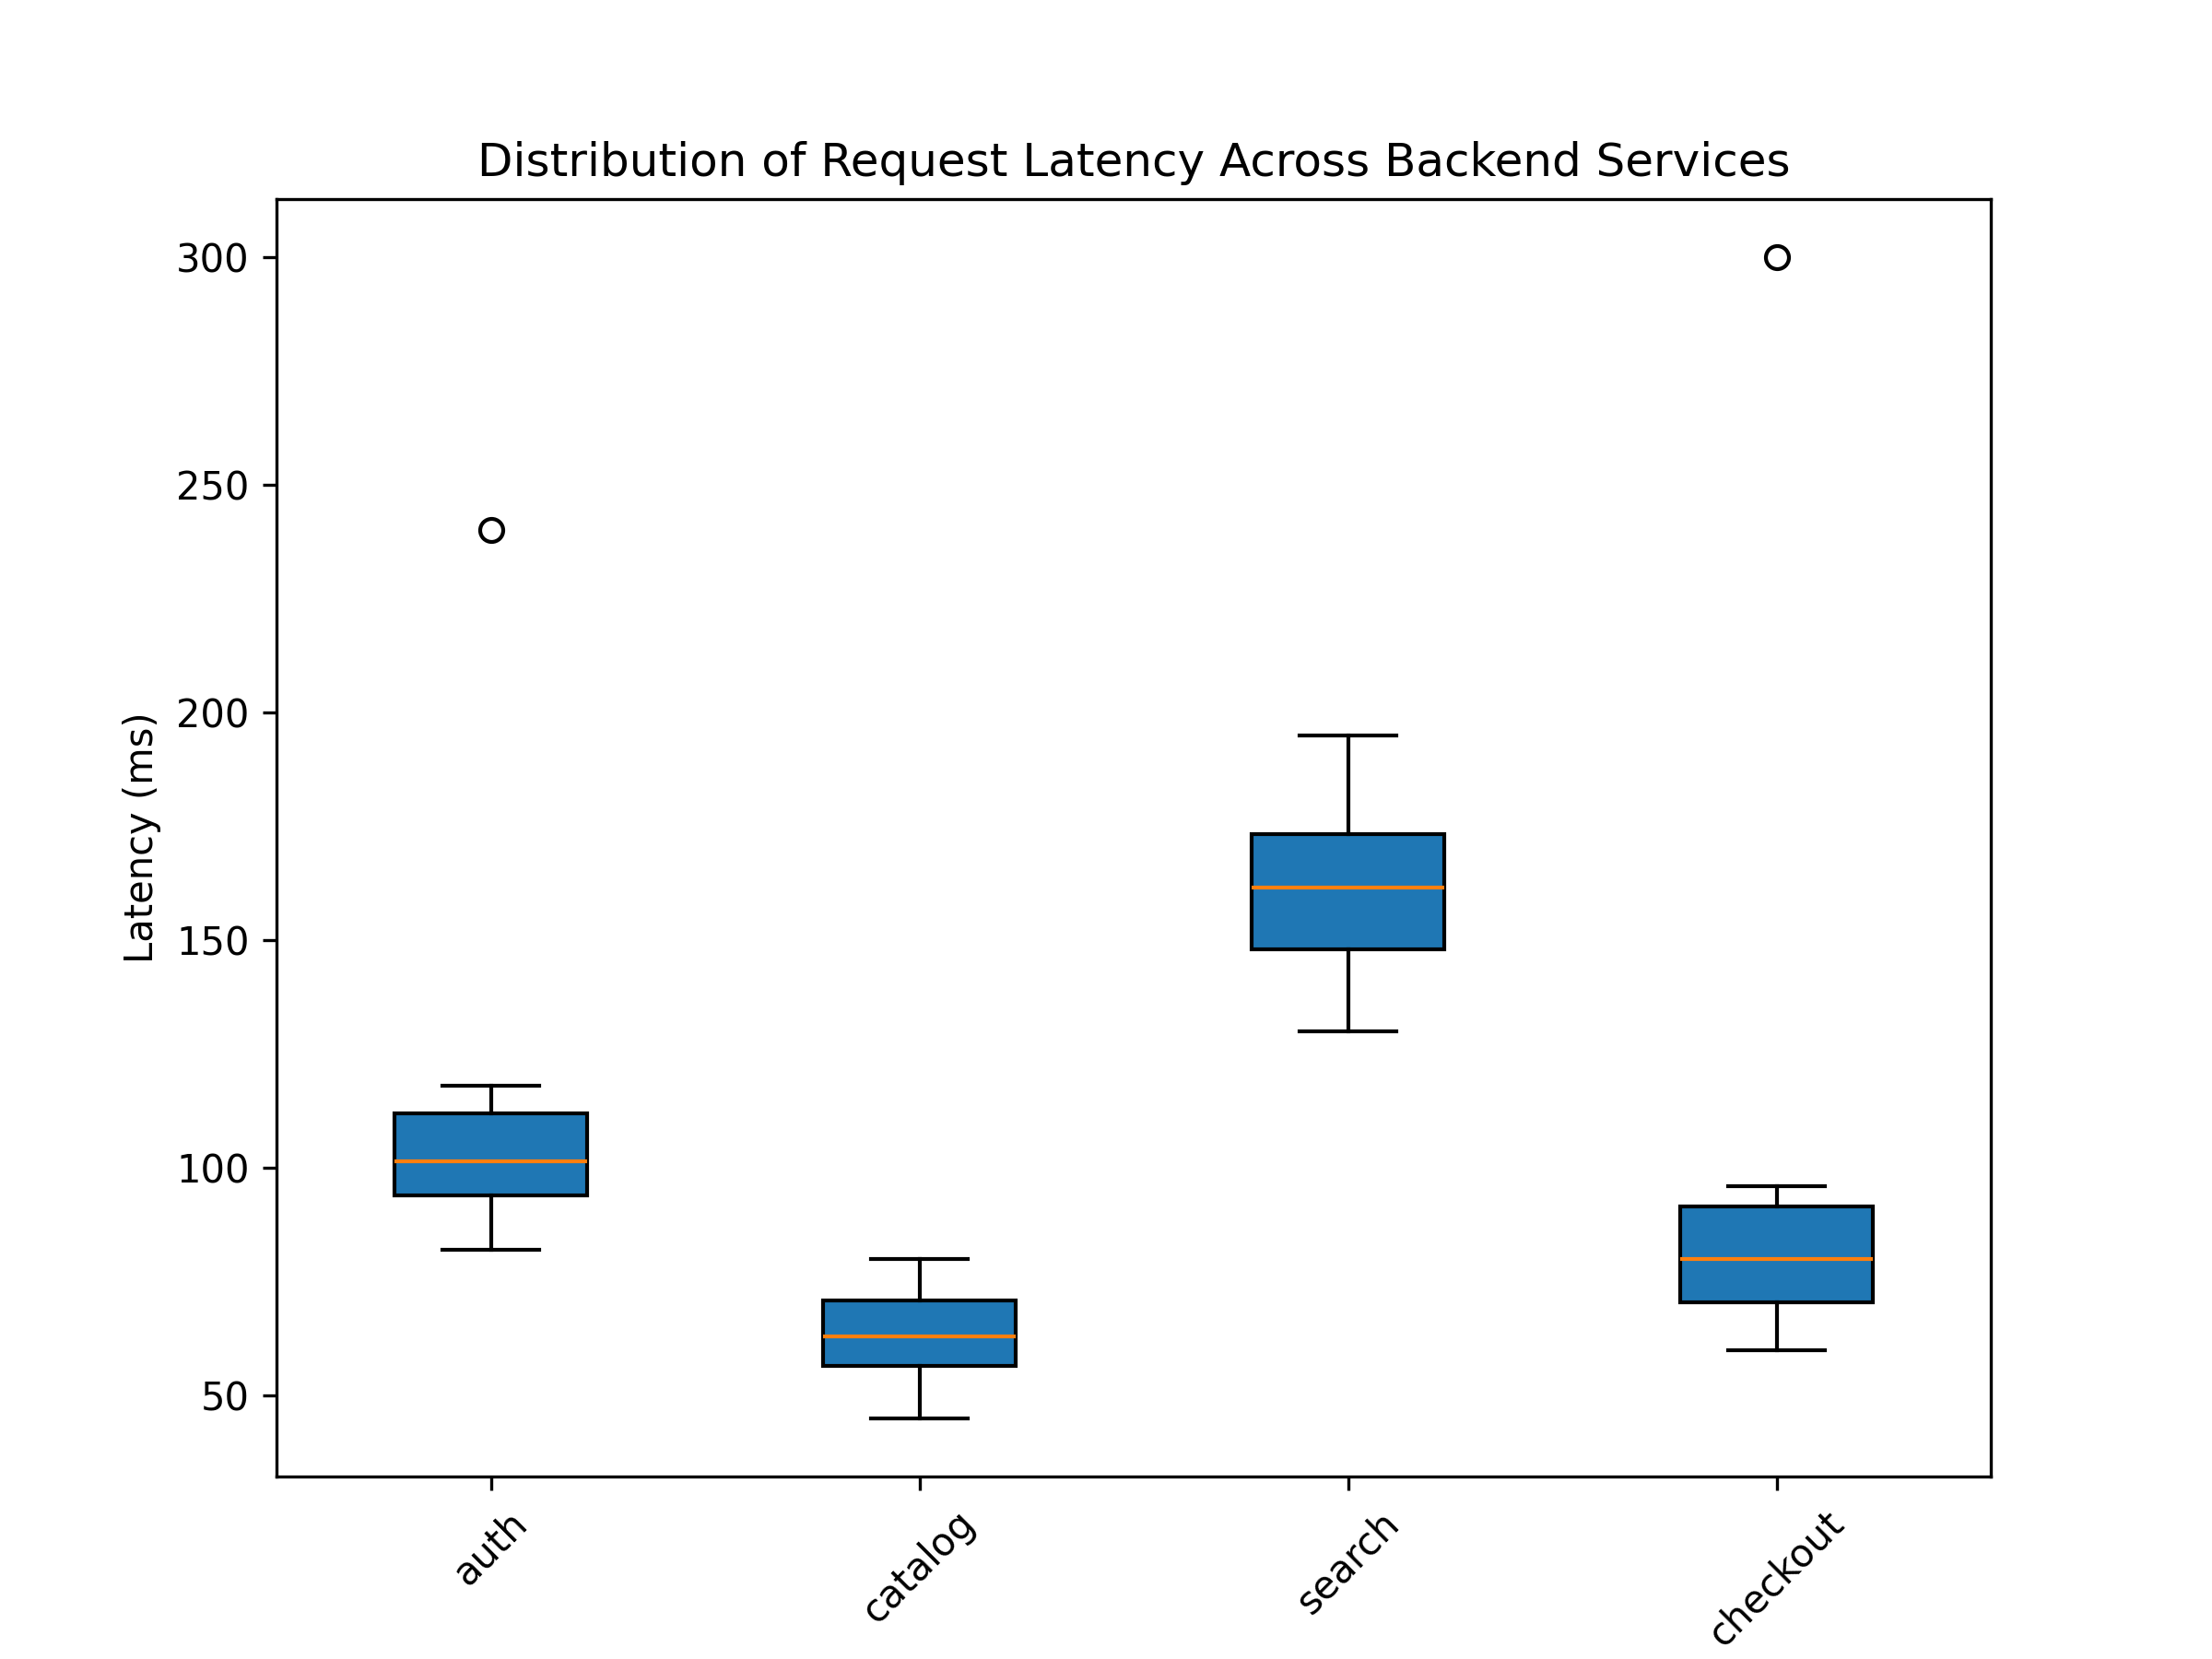

In [2]:
from IPython.display import Image as show_image, display

from validator.solution import image_facts, transcript

run = seed_runs["021"]
print(run.instructions)
print("\nInput files:", list(run.inputs) or "none", "| messages:", len(run.messages))
print("Measured from the PNG:", image_facts(run.figure))
print("\n--- transcript (first 1,400 characters) ---")
print(transcript(run.messages)[:1400])
display(show_image(filename=str(run.figure), width=560))

### 1.2 · Human label, baseline verdict, final verdict

A label and a prediction have the same shape: a list of errors, each with a family and a sentence of evidence. The human label for `021` has one error. The starter baseline in `validator/baseline.py` reports two. Our final validator reports one, the same family as the human. Read the baseline's `wrong_data` evidence closely.

In [3]:
def families_by_run(path, key):
    return {
        item["run_id"]: {error["family"]: error["evidence"] for error in item["errors"]}
        for item in json.loads(path.read_text())[key]
    }


seed_labels = families_by_run(repo / "seed_labels.json", "labels")
baseline = families_by_run(repo / "output" / "baseline_predictions.json", "predictions")
final = families_by_run(repo / "output" / "final_seed_predictions.json", "predictions")

for name, verdicts in (("Human label", seed_labels), ("Baseline", baseline), ("Final validator", final)):
    print(name)
    for family, evidence in verdicts["021"].items():
        print(f"  {family}: {evidence}")
assert set(seed_labels["021"]) == set(final["021"]) == {"wrong_chart"}
assert set(baseline["021"]) == {"wrong_chart", "wrong_data"}

Human label
  wrong_chart: axes 0 is missing xlabel
Baseline
  wrong_data: The plotted data, medians, and outliers match the request, but the chart is missing an x-axis label.
  wrong_chart: The x-axis has service tick labels but lacks an axis label, such as “Backend service,” as required.
Final validator
  wrong_chart: Label the x axis: Service names appear as tick labels, but there is no separate x-axis label identifying the axis.


The baseline's `wrong_data` evidence says the data matches the request, and then cites the missing axis label, which is a design problem. That one sentence is the second of the two error types in §3. Try `"090"` in place of `"021"` in both cells for a second case.

## 2 · How the project unfolded: two phases

The Git history shows two very different ways of working. The contrast between them is one of the main things we learned.

**Phase A, November 5–8: offline first, 14 sessions.** At the start we decided not to use Modal, and to bring our own models and our own Docker sandbox (§9 explains why). Each step was gated. Code and offline tests came first, and every paid API request needed a separate approval. This phase produced the provider adapters that the final runner uses, some small judge pilots on hand-picked runs, and a detailed container pipeline that was tested thoroughly but never built.

**Phase B, the evening of November 8: the `finish-assignment` branch.** We used the Assignment 1 sandbox directly, wrote a plain Dockerfile, and ran each part end to end on the full data: the baseline, Part 2, the 15 agent runs, labels, Part 4, Harbor and the report.

The next cell lists the merged pull requests from the repository's history, in Vancouver time.

In [4]:
def git(*arguments):
    environment = dict(os.environ, TZ="America/Vancouver")
    return subprocess.run(["git", "-C", str(repo), *arguments], capture_output=True, text=True,
                          check=True, env=environment).stdout.splitlines()


merges = []
for line in git("log", "--first-parent", "--reverse", "--date=format-local:%a %b %d %H:%M",
                "--format=%ad|%H|%s", SOURCE_COMMIT):
    date, commit, subject = line.split("|", 2)
    found = re.search(r"pull request #(\d+) from [^/]+/(\S+)", subject)
    if found:
        merges.append((int(found.group(1)), date, commit, found.group(2)))

for number, date, _, branch in merges:
    print(f"{date}   PR #{number:<3} {branch}")

Thu Nov 05 13:05   PR #1   feature/phase-0-offline-evaluation
Thu Nov 05 13:15   PR #2   feature/learning-progress-journal
Thu Nov 05 21:31   PR #3   feature/session-002-offline-preflight
Thu Nov 05 21:42   PR #4   feature/session-003-semantic-validator
Thu Nov 05 22:08   PR #5   feature/session-004-vision-evaluation
Thu Nov 05 23:08   PR #6   feature/session-005-seed-evaluation
Sat Nov 07 00:33   PR #7   feature/session-006-controlled-evaluation
Sat Nov 07 16:58   PR #8   feature/session-008-provider-adapters
Sat Nov 07 17:57   PR #9   feature/session-009-provider-compatibility
Sat Nov 07 23:49   PR #10  feature/session-010-chart-agent-controller
Sun Nov 08 00:07   PR #11  feature/session-011-chart-runtime
Sun Nov 08 00:30   PR #12  feature/session-012-docker-smoke-preflight
Sun Nov 08 12:51   PR #13  feature/session-013-docker-smoke-readiness
Sun Nov 08 13:08   PR #14  feature/session-014-chart-worker-image-staging
Sun Nov 08 13:12   PR #15  docs/session-014-merge-handoff
Sun Nov 08 

PRs #1–#15 are Phase A: one branch per session, each reviewed and merged separately. PR #16 is Phase B, the whole assignment in one branch.

### 2.1 · Early pilots on two hand-picked runs

Before writing a full validator, we asked a small vision model (`gpt-5.4-mini`) single yes/no questions about two seed runs, `004` and `008`, and compared each answer with the human label only after it was saved. In Session 007 we then rewrote the `wrong_chart` prompt (v2) to fix a false positive on `008`. The saved decisions are still in `output/`.

In [5]:
def outcome(predicted, actual):
    return {(True, True): "TP", (True, False): "FP", (False, True): "FN", (False, False): "TN"}[(predicted, actual)]


print(f"{'run':5s}{'family':15s}{'prompt':8s}{'judge says':12s}{'human label':13s}outcome")
for path in sorted((repo / "output").glob("session00*_openai_*_decision.json")):
    decision = json.loads(path.read_text())
    actual = decision["family"] in seed_labels[decision["run_id"]]
    print(f"{decision['run_id']:5s}{decision['family']:15s}{decision.get('prompt_version', 'v1'):8s}"
          f"{str(decision['has_error']):12s}{str(actual):13s}{outcome(decision['has_error'], actual)}")

run  family         prompt  judge says  human label  outcome
004  hard_to_read   v1      False       False        TN
004  wrong_chart    v1      True        True         TP
004  wrong_data     v1      True        True         TP
008  hard_to_read   v1      True        True         TP
008  wrong_chart    v1      True        False        FP
008  wrong_data     v1      True        True         TP
004  wrong_chart    v2      False       True         FN
008  wrong_chart    v2      False       False        TN


The v2 prompt fixed `008` (FP → TN) and broke `004` (TP → FN). With two runs there is no way to tell whether a prompt is better or only different, and the change was never merged. After this, every validator change was scored on all 110 seed runs (§4). Two identical passes of the Part 2 validator later differed by about 0.01 macro-MCC, so we treat differences that small as noise.

### 2.2 · One interface for three providers

Our three agents use different APIs. DeepSeek and OpenAI use the Responses API, and Z.ai uses Chat Completions. DeepSeek's endpoint is also stateless, so the client has to resend the whole conversation on every step. `integrations/providers/` builds each provider's request and turns every reply into the same `NormalizedReply`: text, tool calls, token usage, and the items to send back on the next turn. Before any agent ran, each model received exactly one compatibility request with a tool definition, and the result was saved.

In [6]:
from integrations.models import MODELS

print("Model registry (integrations/models.py):")
for role, spec in MODELS.items():
    print(f"  {role:19s}{spec.provider:9s}{spec.model_id:16s}{spec.api_style:17s}key from {spec.key_env}")

print("\nOne-request compatibility probes (output/provider_compat_*.json):")
for path in sorted((repo / "output").glob("provider_compat_*.json")):
    probe = json.loads(path.read_text())
    detail = (f"{probe['usage']['total_tokens']} tokens, tool called: {probe['expected_tool_called']}"
              if probe["status"] == "completed" else f"{probe['error_type']}, retries: {probe['retries']}")
    print(f"  {probe['role']:19s}{probe['requested_model']:16s}{probe['status']:10s}{detail}")

Model registry (integrations/models.py):
  agent_a            deepseek deepseek-flash  responses        key from DEEPSEEK_API_KEY
  agent_b            openai   gpt-5.6-luna    responses        key from OPENAI_API_KEY
  agent_c            zai      glm-5.3-flash   chat_completions key from ZAI_API_KEY
  experimental_judge openai   gpt-6.1-terra   responses        key from OPENAI_API_KEY

One-request compatibility probes (output/provider_compat_*.json):
  agent_a            deepseek-flash  completed 405 tokens, tool called: True
  agent_b            gpt-5.6-luna    completed 127 tokens, tool called: True
  agent_c            glm-4.7-flash   failed    RateLimitError, retries: 0
  agent_c            glm-5.3-flash   completed 227 tokens, tool called: True
  experimental_judge gpt-6.1-terra   completed 288 tokens, tool called: False


The free `glm-4.7-flash` endpoint answered with a rate-limit error, so Agent C became the paid `glm-5.3-flash`. The probes used no retries on purpose, so that a failure would be visible. The final runner does retry rate limits with backoff, through the OpenAI SDK's `max_retries=6`. The judge probe sent a synthetic image and checked that the reply matched a strict JSON schema. It did not measure accuracy.

### 2.3 · The container pipeline we never built

Phase A also designed its own way to run agent code: a chart controller, a fake Docker gateway for tests, a file-transfer protocol and a verified build context for a chart image. The next cell imports the final agent runner and lists which `integrations` modules it actually loads. It then counts the offline tests written for each part of the code.

In [7]:
import types

# workflow.generate imports `modal` at the top for the course's Modal runner, which we never call.
if importlib.util.find_spec("modal") is None:
    sys.modules["modal"] = types.ModuleType("modal")

import workflow.sandbox_generate as sandbox_generate

package = repo / "integrations"
modules = sorted("integrations." + ".".join(path.relative_to(package).with_suffix("").parts)
                 for path in package.rglob("*.py") if path.name != "__init__.py")
loaded = [name for name in modules if name in sys.modules]
print("Loaded by the final runner:", ", ".join(name.removeprefix("integrations.") for name in loaded))
print("Never loaded:             ", ", ".join(name.removeprefix("integrations.") for name in modules
                                             if name not in sys.modules))

groups = {
    "Phase A container pipeline": ("test_chart_", "test_controller_", "test_sandbox_gateway_", "test_task_artifacts_"),
    "Provider adapters and probes": ("test_provider_",),
    "Validator and dataset": ("test_validator_", "test_offline_"),
    "Final agent runner": ("test_sandbox_generate_",),
}
print()
for group, prefixes in groups.items():
    files = [path for path in sorted((repo / "tests").glob("test_*.py")) if path.name.startswith(prefixes)]
    count = sum(len(re.findall(r"^    def test_", path.read_text(), re.M)) for path in files)
    print(f"{group:30s}{len(files):3d} files {count:4d} tests")

Loaded by the final runner: models, providers.base, providers.client, providers.deepseek, providers.openai, providers.zai
Never loaded:              chart_build_context, chart_controller, chart_image_recipe, chart_transfer, chart_wheel_lock, judge, sandbox_gateway, task_artifacts

Phase A container pipeline      8 files  106 tests
Provider adapters and probes    5 files   37 tests
Validator and dataset           5 files   45 tests
Final agent runner              1 files    5 tests


The final runner loads the model registry and the provider adapters, and nothing else from `integrations/`. The container pipeline, with 106 tests behind it, never ran an agent, because no image was built during Phase A. (`integrations/judge.py` is unused as well: the final judge goes through `validator/model.py`.) Two ideas from that work did reach the final `sandbox/Dockerfile`: the base image is pinned by digest, and the plotting packages install from a hash-locked requirements file.

### 2.4 · Phase B: finishing on the real data

The next cell lists the commits on the `finish-assignment` branch, the branch PR #16 merged.

In [8]:
finish_merge = next(commit for number, _, commit, _ in merges if number == 16)
for line in git("log", "--reverse", "--date=format-local:%b %d %H:%M", "--format=%ad  %s",
                f"{finish_merge}^1..{finish_merge}^2"):
    print(line)

Nov 08 18:42  Wire Terra judge and Docker-sandboxed agent runner
Nov 08 18:42  Add --workers to validator.runner and a per-family disagreement report
Nov 08 18:52  Baseline predictions on seed runs
Nov 08 18:56  Part 2 validator: artifact-gated execution, requirement checklist, readability call
Nov 08 19:04  Part 3: five authored tasks and their Harbor packages with two mutants
Nov 08 19:10  Part 2 predictions on seed runs
Nov 08 19:22  Track labels.json; start OpenAI judges on max_completion_tokens; Part 2 notes
Nov 08 19:23  Part 2 seed predictions (pass 2) and Part 3 runs
Nov 08 19:28  Draft labels for the 15 authored runs; Part 4 validator changes
Nov 08 19:33  Reviewed labels, final predictions, Harbor check
Nov 08 19:36  Part 4b: overlays count only when they hide information; keep 4a results
Nov 08 19:38  Draft report.tex and AI_USAGE.md (final Part 4b numbers and Harbor rewards pending)
Nov 08 19:45  Final validator: Part 2 + legibility kind; overlay inventory behind a switch
N

The commits come in the order of the assignment: wire up the judge and the sandboxed runner, run the baseline, add Part 2, write the Part 3 tasks and Harbor packages, record the runs and labels, run Part 4, then the report. Commit times show when work was saved, not how long it took, but the whole branch was committed in one evening.

> **What we learned.** Process has a cost too. Phase A's caution paid off where it touched something real: one probe per API, pinned dependencies, and keys kept away from agent code. It cost the most where it guarded things that did not exist yet. After three days there were 197 passing offline tests and no chart drawn by an agent. Phase B finished every part by building the thinnest version that worked end to end and measuring it, while keeping the safety measures that mattered from the start.

## 3 · Part 1: Diagnose the starter baseline

### 3.1 · Scoring a validator with MCC

`workflow/evaluate.py` scores each family as its own yes/no classification over the runs. With true and false positives and negatives $TP, TN, FP, FN$, the Matthews correlation coefficient is

$$\mathrm{MCC} = \frac{TP \cdot TN - FP \cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$$

It is 1 for perfect agreement and 0 for a validator that carries no information, and it stays informative when one class is rare. Accuracy would not: 12 of the 110 runs are execution failures, so a validator that never reports one is already 89% accurate. The macro-MCC is the plain mean over the four families. A run labelled `execution_failure` is scored on that family alone and left out of the other three, because a figure that does not exist says nothing about data or design. That is why `wrong_data` has 98 scored runs.

Compute `wrong_data` by hand for the starter baseline, then score all four families with the repository's scorer.

In [9]:
from math import sqrt

import matplotlib.pyplot as plt

from validator.prediction import ERROR_FAMILIES
from workflow.evaluate import score

tp = tn = fp = fn = 0
for run_id, label in seed_labels.items():
    if "execution_failure" in label:
        continue
    actual, said = "wrong_data" in label, "wrong_data" in baseline[run_id]
    tp += actual and said
    tn += not actual and not said
    fp += said and not actual
    fn += actual and not said
by_hand = (tp * tn - fp * fn) / sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
print(f"Baseline wrong_data by hand: TP={tp} TN={tn} FP={fp} FN={fn} over {tp + tn + fp + fn} runs, "
      f"MCC={by_hand:.4f}\n")

baseline_report = score(repo / "seed_labels.json", repo / "output" / "baseline_predictions.json")
assert abs(baseline_report["wrong_data"]["mcc"] - by_hand) < 1e-12
print(f"{'family':20s}{'TP':>4s}{'TN':>4s}{'FP':>4s}{'FN':>4s}{'MCC':>8s}")
for family in ERROR_FAMILIES:
    row = baseline_report[family]
    print(f"{family:20s}{row['tp']:4d}{row['tn']:4d}{row['fp']:4d}{row['fn']:4d}{row['mcc']:8.4f}")
print(f"{'macro-MCC':20s}{'':16s}{baseline_report['macro_mcc']:8.4f}")

Baseline wrong_data by hand: TP=22 TN=27 FP=46 FN=3 over 98 runs, MCC=0.2363

family                TP  TN  FP  FN     MCC
execution_failure      8  93   5   4  0.5945
wrong_data            22  27  46   3  0.2363
wrong_chart           66  18   9   5  0.6286
hard_to_read          29  52   7  10  0.6345
macro-MCC                             0.5235


Two rows stand out. `wrong_data` flags 46 of 73 clean runs, so its MCC is 0.24. `execution_failure` scores only 0.59, though whether a PNG exists is the easiest question in the whole task. Reading the baseline's evidence next to the human labels for these two families gave the two error types the assignment asks for.

### 3.2 · Error type A: execution judged from the story, not the file

The baseline shows the judge the trajectory and asks whether the run failed. The cell compares that verdict with the one fact that decides it: whether a figure was saved.

In [10]:
has_figure = {run_id: run.figure is not None for run_id, run in seed_runs.items()}
truth = {run_id: "execution_failure" in seed_labels[run_id] for run_id in seed_runs}
assert all(truth[run_id] == (not has_figure[run_id]) for run_id in seed_runs)
print(f"Labelled execution_failure: {sum(truth.values())} runs, exactly the runs with no figure.png")

predicted = {run_id: "execution_failure" in baseline[run_id] for run_id in seed_runs}
false_alarms = [run_id for run_id in seed_runs if predicted[run_id] and not truth[run_id]]
missed = [run_id for run_id in seed_runs if truth[run_id] and not predicted[run_id]]
print("Baseline reported a failure although a PNG exists:", false_alarms)
print("Baseline missed a run with no PNG:", missed)
for run_id in false_alarms:
    status = (seed_runs[run_id].messages[-1].get("extra") or {}).get("exit_status")
    print(f"  {run_id}: ended with {status!r}; {image_facts(seed_runs[run_id].figure)}")
print("\nBaseline evidence for", false_alarms[0], "->", baseline[false_alarms[0]]["execution_failure"][:240])

Labelled execution_failure: 12 runs, exactly the runs with no figure.png
Baseline reported a failure although a PNG exists: ['026', '047', '081', '191', '205']
Baseline missed a run with no PNG: ['001', '103', '145', '171']
  026: ended with 'LimitsExceeded'; pixel size 794x860; DPI metadata 100; implied figure size 7.94x8.60 inches
  047: ended with 'LimitsExceeded'; pixel size 1000x600; DPI metadata 100; implied figure size 10.00x6.00 inches
  081: ended with 'Submitted'; pixel size 700x700; DPI metadata 100; implied figure size 7.00x7.00 inches
  191: ended with 'RepeatedFormatError'; pixel size 986x921; DPI metadata 100; implied figure size 9.86x9.21 inches
  205: ended with 'RepeatedFormatError'; pixel size 2599x1523; DPI metadata 300; implied figure size 8.66x5.08 inches

Baseline evidence for 026 -> The agent exhausted its limits after producing an invalid figure: it is not a sunburst chart, has no hollow center, and is 794×860 rather than 1000×1000 pixels.


Four of the five false alarms ended by hitting the step limit or by repeated format errors, after the figure had already been saved. The judge read that story and reported a crash, and its evidence for `026` mixes in design complaints about a figure that exists. The cost spreads further: the baseline stops at an execution failure, so these five runs also lost 11 true positives in the other three families. In the other direction, four runs with no figure were not flagged. Three were judged acceptable, and `103` was given data, design and readability errors for a chart that does not exist.

### 3.3 · Error type B: one question per family, and any problem counts

The baseline asks four separate yes/no questions, such as "does the plotted data differ from what was requested in any way?". Take every seed run where it answered yes for `wrong_data` and the human label has none, and see what the human label says instead.

In [11]:
def wrong_data_false_positives(predictions):
    return [run_id for run_id, label in seed_labels.items()
            if "execution_failure" not in label
            and "wrong_data" in predictions[run_id] and "wrong_data" not in label]


flagged = wrong_data_false_positives(baseline)
design = [run_id for run_id in flagged if "wrong_chart" in seed_labels[run_id]]
print(f"Baseline: {len(flagged)} wrong_data false positives, {len(design)} of them on runs "
      "the humans labelled wrong_chart")

run_id = "090"
print(f"\nRun {run_id}")
print("  human   :", seed_labels[run_id])
print("  baseline:", baseline[run_id]["wrong_data"])
assert len(flagged) == len(design) == 46

Baseline: 46 wrong_data false positives, 46 of them on runs the humans labelled wrong_chart

Run 090
  human   : {'wrong_chart': 'axes 0 is missing xlabel'}
  baseline: The plotted data and median markers match the request, but the x-axis is missing its axis label.


All 46 false positives are runs with a real design error. Asked whether the data differs in any way, the judge said yes to any problem it noticed, often while saying in the same sentence that the data was right. The same confusion ran in other directions too: data errors filed as `wrong_chart`, and readability problems the judge noticed and then filed elsewhere.

> **Takeaway from Part 1.** Both error types come from asking the model questions it cannot keep apart. The baseline asked a model to infer a fact that a file check settles, and it let the choice of question decide the error family. Part 2 removes the model from the first decision and takes the family decision away from the judge's choice of question.

## 4 · Part 2: Two validator changes

### 4.1 · Decide `execution_failure` from the file

`judge_execution` in `validator/solution.py` looks only at the artifact. A `figure.png` that is missing, has another format, or fails to decode is an execution failure. That result is final and needs no model call. Run it on all 110 seed runs and compare it with the human labels.

In [12]:
from validator.solution import judge_execution

gate = {run_id: bool(judge_execution(run)) for run_id, run in seed_runs.items()}
print("Flagged by the file check:", sum(gate.values()), "| labelled execution_failure:", sum(truth.values()))
assert gate == truth

Flagged by the file check: 12 | labelled execution_failure: 12


The file check agrees with every seed label, so this family now scores exactly 1.0, and the five runs from §3.2 go on to the judge calls. The check is also strict about damaged files. Make two broken copies of a good figure and pass them through the same function.

In [13]:
import tempfile
from dataclasses import replace

from PIL import Image

scratch = Path(tempfile.mkdtemp(prefix="walkthrough_"))
good = seed_runs["021"].figure

truncated = scratch / "truncated" / "figure.png"
truncated.parent.mkdir()
truncated.write_bytes(good.read_bytes()[: good.stat().st_size // 2])

renamed_jpeg = scratch / "jpeg" / "figure.png"
renamed_jpeg.parent.mkdir()
with Image.open(good) as image:
    image.convert("RGB").save(renamed_jpeg, format="JPEG")

for label, figure in (("original", good), ("truncated", truncated),
                      ("JPEG named figure.png", renamed_jpeg), ("no file", None)):
    errors = judge_execution(replace(seed_runs["021"], figure=figure))
    print(f"{label:22s} -> {errors[0].evidence if errors else 'valid PNG, continue to the judge calls'}")

original               -> valid PNG, continue to the judge calls
truncated              -> The final figure.png cannot be decoded as a complete PNG (OSError).
JPEG named figure.png  -> The final figure.png is not a PNG (detected JPEG).
no file                -> No final figure.png was produced.


### 4.2 · Two structured judge calls

For a run with a valid figure, `validate` makes two calls to the vision judge. Both use a strict JSON schema, so a reply is either machine-readable or rejected, and one malformed reply gets one retry.

1. **Requirement checklist.** The judge lists every requirement in the instruction, tags each one `data`, `design` or `legibility`, and marks it `met`, `violated` or `unclear` with evidence. `wrong_data` is reported only if a `data` item is violated, and `wrong_chart` only if a `design` item is violated. The family now follows from the tag, not from which question was asked. The prompt includes the official definitions of each kind, the input files, the clipped transcript, and *image facts* measured from the PNG (pixel size, DPI, implied size in inches, blank image), so the judge checks size and DPI requirements against numbers instead of guessing.
2. **Readability.** A separate call looks only at the image, for clipped, overlapping, hidden or low-contrast content, and is told that missing or wrong elements are not readability problems. Only issues rated `major` count as `hard_to_read`.

Here a scripted function stands in for `validator.model.complete`, so you can see the exact request and how a reply becomes a prediction. The reply text below is written by hand for run `021`. The parsing and the family mapping are the real code.

In [14]:
from unittest.mock import patch

import validator.solution as solution


def scripted_judge(*replies):
    calls = []

    def complete(messages, **options):
        calls.append({"messages": messages, "options": options})
        reply = replies[len(calls) - 1]
        return {"choices": [{"message": {"content": json.dumps(reply)}}]}

    return complete, calls


checklist_reply = {"requirements": [
    {"requirement": "One box per service in the given order", "kind": "data",
     "status": "met", "evidence": "auth, catalog, search, checkout from left to right"},
    {"requirement": "Label the x axis", "kind": "design",
     "status": "violated", "evidence": "tick labels are present but the axis has no label"},
]}
readability_reply = {"issues": [
    {"category": "squeezed_layout", "where": "catalog box", "severity": "minor",
     "description": "the box is short but its median is readable"},
]}

fake, calls = scripted_judge(checklist_reply, readability_reply)
with patch.object(solution, "complete", fake):
    errors = solution.validate(seed_runs["021"])

for number, call in enumerate(calls, start=1):
    parts = call["messages"][0]["content"]
    schema = call["options"]["response_format"]["json_schema"]["name"]
    print(f"Call {number}: schema={schema}, text parts={sum(p['type'] == 'text' for p in parts)}, "
          f"images={sum(p['type'] == 'image_url' for p in parts)}")
print("\n--- start of the checklist prompt ---")
print(calls[0]["messages"][0]["content"][0]["text"][:900])
print("\nPrediction:", [(error.family.value, error.evidence) for error in errors])
assert [error.family.value for error in errors] == ["wrong_chart"]

Call 1: schema=requirement_checklist, text parts=1, images=1
Call 2: schema=readability_issues, text parts=1, images=1

--- start of the checklist prompt ---
You are auditing the output of a data-visualisation agent.

Make a checklist of EVERY requirement stated or clearly implied by the task
instruction below, one item per checkable requirement, then check each one
against the rendered figure (attached). Use the agent's code, the input files
and the image facts as supporting evidence for what values were plotted, but
judge the figure that was actually saved.

Tag each requirement with exactly one kind:
`data` requirements are about WHAT is plotted: which values, series, categories,
groups, columns, rows, subsets or filters; aggregation, scaling, normalisation
and formulas; the range or grid a function is sampled on; which dimension of
the data each encoding carries (bubble size, colour value, error bar); and the
ORDER of points, bars, categories or sequences, including requested sorti

Change the first item's `status` to `"violated"` and rerun. The prediction gains `wrong_data`, with that item's evidence. Change the readability issue to `"major"` and it gains `hard_to_read`. A missing axis label can no longer be filed under `wrong_data`, because the family comes from the item's `kind`.

### 4.3 · Results on the 110 seed runs

Score the three committed seed prediction files: the starter baseline, the Part 2 validator, and the final validator after Part 4 (§7).

Baseline  macro-MCC = 0.5235
Part 2    macro-MCC = 0.8747
Final     macro-MCC = 0.8726


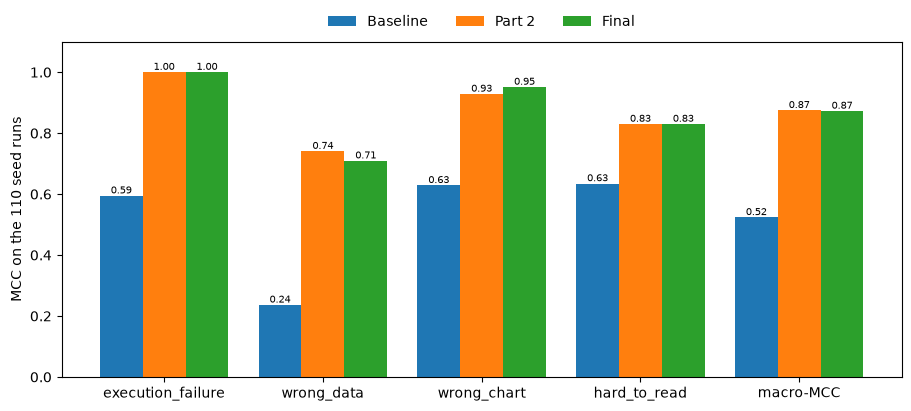


wrong_data false positives: baseline 46 -> final 9, 9 of them on runs with a design error


In [15]:
seed_stages = {
    "Baseline": "baseline_predictions.json",
    "Part 2": "pre_iteration_seed_predictions.json",
    "Final": "final_seed_predictions.json",
}
seed_reports = {
    stage: score(repo / "seed_labels.json", repo / "output" / filename)
    for stage, filename in seed_stages.items()
}

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
columns = [*ERROR_FAMILIES, "macro_mcc"]
for offset, (stage, report) in enumerate(seed_reports.items()):
    values = [report[name]["mcc"] if name != "macro_mcc" else report[name] for name in columns]
    bars = ax.bar([x + (offset - 1) * 0.27 for x in range(len(columns))], values, width=0.27, label=stage)
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
    print(f"{stage:9s} macro-MCC = {report['macro_mcc']:.4f}")
ax.set_xticks(range(len(columns)), [name.replace("macro_mcc", "macro-MCC") for name in columns])
ax.set(ylabel="MCC on the 110 seed runs", ylim=(0, 1.1))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=3, frameon=False)
plt.show()

flagged_final = wrong_data_false_positives(final)
print(f"\nwrong_data false positives: baseline {len(flagged)} -> final {len(flagged_final)}, "
      f"{sum('wrong_chart' in seed_labels[r] for r in flagged_final)} of them on runs with a design error")
assert [round(report["macro_mcc"], 4) for report in seed_reports.values()] == [0.5235, 0.8747, 0.8726]
assert len(flagged_final) == 9

Every family improved, and `wrong_data` improved most, from 0.24 to above 0.7. The nine `wrong_data` false positives that remain are again runs with a design error: the judge still sometimes tags a design requirement as `data`. To read every remaining disagreement with its evidence, run `scripts/disagreements.py` on a prediction file.

The final macro-MCC is 0.0021 below the Part 2 pass. Two passes of the same Part 2 validator at temperature 0 differed by about 0.01, so this difference is noise. The Part 4 change had no measurable effect on the seed set in either direction, which matches what it was for (§7).

> **Takeaway from Part 2.** Decide with code whatever code can decide. Give the model a structured job (list the requirements, tag them, mark them) and derive the answer from its output. A free-form verdict is harder to correct. Measure the run-to-run noise before claiming a gain.

## 5 · The agent sandbox: running untrusted model code

For Part 3, three agents had to write and run plotting code for our new tasks. That code is untrusted: the agent's only tool runs any shell command it chooses. The course runs its agents on Modal. We built our own runner, `workflow/sandbox_generate.py`, around the Docker sandbox we wrote in Assignment 1. That sandbox is a pinned Git dependency in `pyproject.toml`, not a copy.

```text
 host process (holds the API keys)                Docker container (fresh for every run)
 ─────────────────────────────────                ───────────────────────────────────────
 workflow/sandbox_generate.py                      image hw2-chart:1, user "agent", /workspace
   build the prompt from task.json                 no network, all capabilities dropped,
   call the model API ─► reply with a bash call    no-new-privileges, 2 CPUs, 2 GB memory
   ───── command ────────────────────────────────► run it, at most 120 s
   ◄──── {returncode, output}, clipped to 10 kB ──
   repeat: at most 20 steps and 15 minutes         holds task.json and the input CSVs only
   copy figure.png out ◄────────────────────────── figure.png
   check it is a PNG, write runs/<task>__<agent>/result.json
```

| Control | Where it lives | What it protects against |
| --- | --- | --- |
| A fresh container for every run | `DockerWorkspace` | State leaking between runs or between agents |
| `network="none"` | `DockerWorkspace` | Sending data out, or installing other packages |
| Keys only in the host process | `_client` | The agent reading a key from its environment |
| Base image pinned by digest, packages installed with `--require-hashes` | `sandbox/Dockerfile` | A changed dependency; every run gets the same plotting stack |
| Unprivileged user, dropped capabilities, CPU, memory and process limits, a container lifetime cap | The Assignment 1 `Sandbox` | Runaway or hostile commands |
| Only `figure.png` is copied back, at most 20 MB | `DockerWorkspace.get` | The host reading anything else the agent wrote |
| Same limits and prompt as the course (20 steps, 120 s per command, 15 min, submit marker) | Constants at the top of the runner | Runs comparable with the seed trajectories and readable by the same validator |

This is a development sandbox, not a guarantee against a determined attacker on shared hardware. The `--local` option runs commands directly on the host, has no isolation, and exists only for smoke tests.

### 5.1 · The pieces in the source

In [16]:
import inspect

pin = next(line.strip() for line in (repo / "pyproject.toml").read_text().splitlines()
           if "agent-sandbox-runtime" in line)
print("pyproject.toml dependency on the Assignment 1 sandbox:\n ", pin, "\n")
print("sandbox/Dockerfile:")
print("\n".join(line for line in (repo / "sandbox" / "Dockerfile").read_text().splitlines()
                if line and not line.startswith("#")))
print(f"\nLimits: {sandbox_generate.STEP_LIMIT} steps, {sandbox_generate.COMMAND_TIMEOUT_SECONDS} s per command, "
      f"{sandbox_generate.WALL_TIME_LIMIT_SECONDS // 60} min per run, "
      f"{sandbox_generate.OBSERVATION_CHARS:,} characters of output per observation\n")
print(inspect.getsource(sandbox_generate.DockerWorkspace.__init__))

pyproject.toml dependency on the Assignment 1 sandbox:
  "agent-sandbox-runtime @ git+https://github.com/xqzr2000/cmu-11-768-assignment-1.git@0cb0534c2fffb67ddfff619100057fad0be90a3c#subdirectory=packages/agent-sandbox-runtime", 

sandbox/Dockerfile:
FROM python:3.12-slim@sha256:4840d514c583a4d3d8cad3940e68dee6f0f6f3635c12fcd0a3d74c21a5b93a54
COPY requirements.txt /tmp/requirements.txt
RUN pip install --no-cache-dir --require-hashes --only-binary=:all: -r /tmp/requirements.txt \
    && rm /tmp/requirements.txt \
    && useradd --uid 10001 --create-home agent \
    && mkdir /workspace && chown agent:agent /workspace
ENV MPLBACKEND=Agg \
    PYTHONUNBUFFERED=1 \
    MPLCONFIGDIR=/tmp/matplotlib
USER agent
WORKDIR /workspace

Limits: 20 steps, 120 s per command, 15 min per run, 10,000 characters of output per observation

    def __init__(self, image: str) -> None:
        from agent_sandbox_runtime.sandbox import Sandbox

        self.box = Sandbox(
            image,
            cwd=WOR

### 5.2 · Run the real agent loop with a scripted model

Colab has no Docker and this notebook has no API keys, so the next cell swaps exactly two things in `run_one`, the function that produced the 15 recorded runs. The model client is replaced by a script of three Chat Completions replies in the shape Z.ai returns, and the Docker container by `LocalWorkspace`, a temporary directory on this machine. Request building, reply parsing, the step loop, the submit check, figure extraction and `write_result` are the real code. The scripted commands solve the `quarterly-revenue-by-region` task, so running them here is safe.

Request 1 to glm-5.3-flash: 2 messages, tools=['bash']
Prompt starts: Please solve this issue: TASK ID: quarterly-revenue-by-region  USER REQUEST: Using matplotlib, read transactions.csv. It has one row per order with columns orde ...

agent  $ head -3 transactions.csv && wc -l transactions.csv
sandbox  3001 transactions.csv
agent  $ cat > plot.py <<'EOF' ...
sandbox  -rw-r--r-- 1 root root 26095 Nov 23 12:21 figure.png
agent  $ echo COMPLETE_TASK_AND_SUBMIT_FINAL_OUTPUT
sandbox  COMPLETE_TASK_AND_SUBMIT_FINAL_OUTPUT

exit status: Submitted | figure bytes: 26095
Loaded back as quarterly-revenue-by-region__glm | messages: 9 | inputs: ['transactions.csv'] | execution check: valid PNG


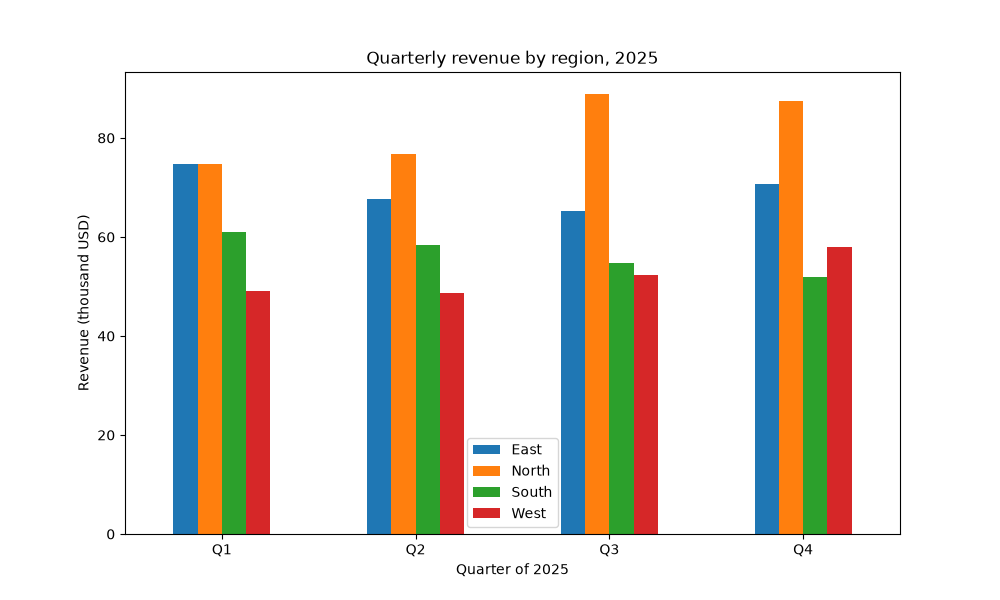

In [17]:
import copy

from workflow.generate import AGENT_BY_KEY, write_result
from workflow.tasks import load_tasks
from validator.runner import Run

PLOT = '''cat > plot.py <<'EOF'
import matplotlib.pyplot as plt
import pandas as pd

orders = pd.read_csv("transactions.csv", parse_dates=["date"])
orders["revenue"] = orders.units * orders.unit_price / 1000
orders["quarter"] = "Q" + orders.date.dt.quarter.astype(str)
table = orders.pivot_table(index="quarter", columns="region", values="revenue", aggfunc="sum")
ax = table[sorted(table.columns)].plot.bar(figsize=(10, 6), rot=0)
ax.set(xlabel="Quarter of 2025", ylabel="Revenue (thousand USD)",
       title="Quarterly revenue by region, 2025")
ax.legend(title=None)
plt.savefig("figure.png", dpi=100)
EOF
python3 plot.py && ls -l figure.png'''
COMMANDS = ["head -3 transactions.csv && wc -l transactions.csv", PLOT, f"echo {sandbox_generate.SUBMIT}"]


class ScriptedChatModel:
    """Stands in for the OpenAI SDK client: returns one canned tool call per request."""

    def __init__(self, commands):
        self.commands, self.requests = list(commands), []
        self.chat = types.SimpleNamespace(completions=types.SimpleNamespace(create=self.create))

    def create(self, **request):
        self.requests.append(copy.deepcopy(request))
        step = len(self.requests)
        call = {"id": f"call_{step}", "type": "function",
                "function": {"name": "bash", "arguments": json.dumps({"command": self.commands[step - 1]})}}
        return {"model": "scripted", "usage": {"prompt_tokens": 0, "completion_tokens": 0},
                "choices": [{"finish_reason": "tool_calls",
                             "message": {"content": f"Step {step}.", "tool_calls": [call]}}]}


tasks = {task.task_id: (task, descriptor) for task, descriptor in load_tasks(repo / "tasks")}
task, descriptor = tasks["quarterly-revenue-by-region"]
model = ScriptedChatModel(COMMANDS)
with patch.object(sandbox_generate, "_client", lambda spec: model), \
     patch.object(sandbox_generate, "DockerWorkspace", lambda image: sandbox_generate.LocalWorkspace()):
    result = sandbox_generate.run_one(task, descriptor, AGENT_BY_KEY["glm"], sandbox_generate.IMAGE, local=False)

first = model.requests[0]
print(f"Request 1 to {first['model']}: {len(first['messages'])} messages, "
      f"tools={[tool['function']['name'] for tool in first['tools']]}")
print("Prompt starts:", first["messages"][1]["content"][:160].replace("\n", " "), "...\n")
for message in result["trajectory"]["messages"][2:]:
    if message["role"] == "assistant":
        command = json.loads(message["tool_calls"][0]["function"]["arguments"])["command"]
        print("agent  $", command.splitlines()[0] + (" ..." if "\n" in command else ""))
    elif message["role"] == "tool":
        print("sandbox ", json.loads(message["content"])["output"].strip().splitlines()[-1][:100])
print("\nexit status:", result["outcome"]["exit_status"], "| figure bytes:", len(result["artifact_bytes"]))

demo_runs = scratch / "demo_runs"
written = write_result(task, descriptor, AGENT_BY_KEY["glm"], demo_runs, result, force=True)
demo = Run.load(written, demo_runs.parent)
print("Loaded back as", demo.run_id, "| messages:", len(demo.messages), "| inputs:", list(demo.inputs),
      "| execution check:", judge_execution(demo) or "valid PNG")
display(show_image(filename=str(demo.figure), width=520))

The loop sent the system prompt, the task prompt and the `bash` tool, ran each command it got back, and returned the output as the next message. It stopped when the output's first line was the submit marker. The run directory it wrote has the same layout as the seed artifacts, so `Run.load` and the validator read it unchanged. This is how the 15 real runs reached the judge.

### 5.3 · The 15 recorded runs

In [18]:
import pandas as pd

authored_runs = {run.run_id: run for run in runs(repo / "runs")}
records = [json.loads(path.read_text()) for path in sorted((repo / "runs").glob("*/result.json"))]
run_table = pd.DataFrame([{
    "task": record["task_id"], "agent": record["agent"]["key"], "model": record["agent"]["model"],
    "exit": record["outcome"]["exit_status"], "model calls": record["outcome"]["usage"]["model_calls"],
    "input tokens": record["outcome"]["usage"]["input_tokens"],
    "output tokens": record["outcome"]["usage"]["output_tokens"],
    "seconds": round(record["elapsed_seconds"], 1), "figure": record["artifact_present"],
} for record in records])
display(run_table)
print(f"{len(run_table)} runs, all submitted: {set(run_table['exit']) == {'Submitted'}}; model calls "
      f"{run_table['model calls'].min()}-{run_table['model calls'].max()}; "
      f"{run_table['seconds'].sum() / 60:.1f} minutes in total")

,task,agent,model,exit,model calls,input tokens,output tokens,seconds,figure
0,dense-department-budgets,deepseek,deepseek-flash,Submitted,6,27397,4598,44.6,True
1,dense-department-budgets,glm,glm-5.3-flash,Submitted,7,16824,1564,55.6,True
2,dense-department-budgets,luna,gpt-5.6-luna,Submitted,4,11844,3456,41.5,True
3,quarterly-revenue-by-region,deepseek,deepseek-flash,Submitted,4,9229,1583,15.7,True
4,quarterly-revenue-by-region,glm,glm-5.3-flash,Submitted,3,4181,412,16.6,True
5,quarterly-revenue-by-region,luna,gpt-5.6-luna,Submitted,4,7760,1520,18.8,True
6,sensor-daily-median,deepseek,deepseek-flash,Submitted,5,14283,2491,24.0,True
7,sensor-daily-median,glm,glm-5.3-flash,Submitted,4,5951,493,24.1,True
8,sensor-daily-median,luna,gpt-5.6-luna,Submitted,4,8113,1463,18.2,True
9,styled-decay-curves,deepseek,deepseek-flash,Submitted,4,7878,1032,12.0,True


15 runs, all submitted: True; model calls 3-7; 6.0 minutes in total


Every agent submitted a figure within seven model calls and under a minute; none hit a limit. The agents were much stronger than the small open-weight models the course prescribes, and that limited what Part 3 could test (§6).

> **Takeaway from the sandbox.** The security boundary follows the process boundary: the process that holds keys never runs model code, and the process that runs model code never holds keys. Using the Assignment 1 sandbox as a pinned dependency, not a copy, means a fix there reaches this project by updating one commit hash. Keeping the course's result format meant the new runs needed no changes to the validator or the scorer.

## 6 · Part 3: Tasks built to expose the validator

We looked for places where the Part 2 validator must be weak because of how it works, and wrote tasks that land there.

1. **Large-input aggregation.** The judge sees each input file clipped to 20,000 characters (`MAX_INPUT_CHARS_PER_FILE`). It cannot recompute a total over thousands of rows. If an agent aggregates wrongly, the chart still looks plausible.
2. **Fine visual detail.** Exact colours, line styles, markers, log scales and long rotated labels are easy for a judge to skim past.

| Task | Class | What it probes |
| --- | --- | --- |
| `quarterly-revenue-by-region` | Large-input aggregation | Grouping 3,000 orders, and revenue (units × price) rather than units |
| `top-products-unit-share` | Large-input aggregation | The right denominator, the top eight, percentages, sorting |
| `sensor-daily-median` | Large-input aggregation | Missing readings, daily medians, sensor filtering, a min–max band |
| `styled-decay-curves` | Fine visual detail | Exact line colours, styles, markers, log scale, grid and legend |
| `dense-department-budgets` | Fine visual detail | Thirty long category names, rotation, layout, readable labels |

The next cell shows how little of a large input the judge sees, then computes the true answer for the revenue task from the full file.

In [19]:
from validator.solution import MAX_INPUT_CHARS_PER_FILE, input_files

for task_id in ("quarterly-revenue-by-region", "top-products-unit-share", "sensor-daily-median"):
    sample = authored_runs[f"{task_id}__luna"]
    name, path = next(iter(sample.inputs.items()))
    text = path.read_text()
    shown = input_files(sample)
    width = len(text.splitlines()[0].split(","))
    rows_shown = sum(1 for line in shown.splitlines()[1:]
                     if len(line.split(",")) == width and line not in text.splitlines()[:1])
    print(f"{task_id:28s} {name:17s} {len(text):>8,} characters, {text.count(chr(10)) - 1:>6,} rows | judge sees "
          f"{min(len(text), MAX_INPUT_CHARS_PER_FILE) / len(text):4.0%} of the text, about {rows_shown} complete rows")

orders = pd.read_csv(authored_runs["quarterly-revenue-by-region__luna"].inputs["transactions.csv"], parse_dates=["date"])
orders["revenue"] = orders.units * orders.unit_price / 1000
orders["quarter"] = "Q" + orders.date.dt.quarter.astype(str)
print("\nTrue answer, revenue in thousand USD:")
display(orders.pivot_table(index="quarter", columns="region", values="revenue", aggfunc="sum").round(1))

quarterly-revenue-by-region  transactions.csv   119,205 characters,  3,000 rows | judge sees  17% of the text, about 502 complete rows
top-products-unit-share      transactions.csv   119,205 characters,  3,000 rows | judge sees  17% of the text, about 502 complete rows


sensor-daily-median          sensors.csv        310,925 characters, 12,096 rows | judge sees   6% of the text, about 777 complete rows

True answer, revenue in thousand USD:


region,East,North,South,West
quarter,,,,
Q1,74.7,74.7,60.9,49.1
Q2,67.6,76.8,58.3,48.6
Q3,65.3,88.9,54.7,52.3
Q4,70.7,87.5,51.9,58.0


For the revenue task the judge sees roughly a sixth of the orders: the first and last 10,000 characters of the file. It can check that the bars have the right labels, order and layout. It cannot check that the East Q1 bar is the right height. The Harbor verifier in §8 can, because it compares the plotted values with this answer key.

### 6.1 · Labelling the 15 runs

Each task was run once with each of the three agents (§5.3). To label a run, we replayed its bash commands in a scratch directory under the same `savefig` hook the Harbor verifiers use (§8). That gives a JSON record of exactly what was drawn: values, order, labels, colours, styles, scales and limits. We compared it with independently computed answer keys and then inspected every figure by eye. Claude drafted the labels this way and Russell reviewed each one against its figure. The grid shows every figure with its final label.

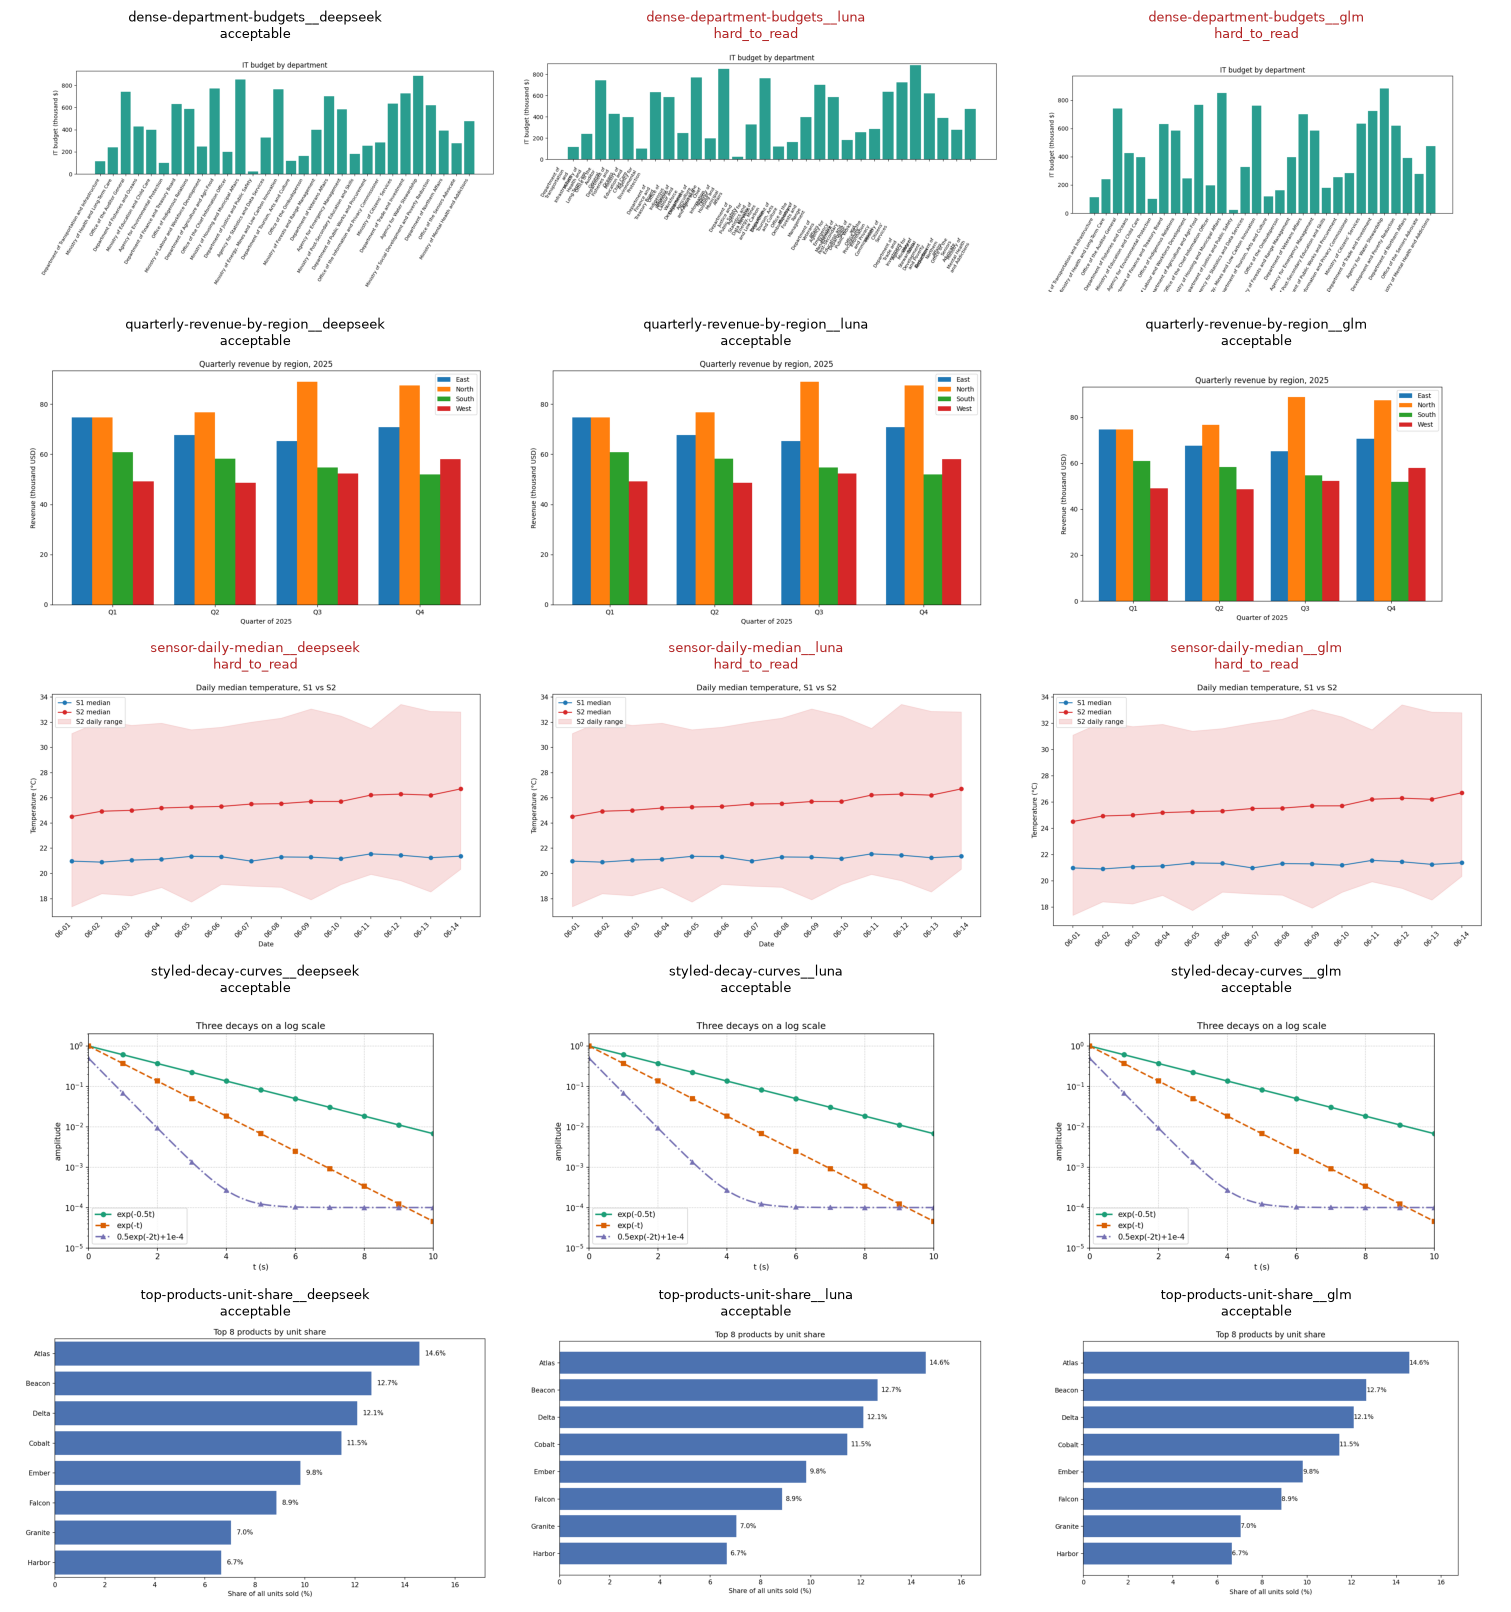

Positive labels among the 15 runs: {'execution_failure': 0, 'wrong_data': 0, 'wrong_chart': 0, 'hard_to_read': 5}


In [20]:
authored_labels = families_by_run(repo / "labels.json", "labels")
task_ids = sorted({run.task_id for run in authored_runs.values()})
agents = ("deepseek", "luna", "glm")

fig, axes = plt.subplots(len(task_ids), len(agents), figsize=(15, 16), layout="constrained")
for row, task_id in enumerate(task_ids):
    for column, agent in enumerate(agents):
        run_id = f"{task_id}__{agent}"
        label = sorted(authored_labels[run_id])
        ax = axes[row, column]
        ax.imshow(plt.imread(authored_runs[run_id].figure))
        ax.set_title(f"{run_id}\n{', '.join(label) or 'acceptable'}", fontsize=9,
                     color="firebrick" if label else "black")
        ax.axis("off")
plt.show()

positives = {family: sum(family in label for label in authored_labels.values()) for family in ERROR_FAMILIES}
print("Positive labels among the 15 runs:", positives)
assert positives == {"execution_failure": 0, "wrong_data": 0, "wrong_chart": 0, "hard_to_read": 5}

Every agent plotted the right values with the requested design. The five errors are all `hard_to_read`: two department-budget charts with clipped or colliding names, and all three sensor charts, where the legend covers the upper edge of the S2 band. With no positive example in three families, the scorer reports their MCC as 0 by convention, so the macro-MCC on this set cannot exceed 0.25.

The Part 2 validator found two of the five readability errors (`hard_to_read` MCC 0.5547) and missed the three sensor legends. It also produced one false `wrong_chart`, on the Luna budget chart, which §7 explains.

> **Takeaway from Part 3.** The agents, not the validator, limited this experiment. No agent got an aggregate wrong, so the judge's inability to check sums was never tested on a real run. Its "acceptable" on those charts is right, but unverified. To test a validator reliably, plant the errors yourself, as the Harbor mutants do (§8), instead of hoping the agents make them.

## 7 · Part 4: Iterate, measure, and keep the better-supported version

### 7.1 · The `legibility` kind and the overlay flag

On the authored runs, the judge filed the instruction that labels must not overlap as a violated `design` item, which produced the `wrong_chart` false positive. Part 4 added a third requirement kind, `legibility`. The checklist lists those items, and they never count toward `wrong_chart`. The readability call decides them.

To catch the three sensor legends, Part 4 also tried an overlay inventory. With `OVERLAY_INVENTORY` on, the readability call receives the whole image plus its four quadrants enlarged, and the judge must list every legend or text box and what lies under it. The next cell runs both settings on `sensor-daily-median__luna`, whose legend covers part of a shaded band.

In [21]:
sensor = authored_runs["sensor-daily-median__luna"]

checklist = {"requirements": [
    {"requirement": "Legend with the three named entries", "kind": "design",
     "status": "met", "evidence": "all three entries are present"},
    {"requirement": "Every label fully visible and not overlapping", "kind": "legibility",
     "status": "violated", "evidence": "the legend sits on the S2 band"},
]}
for flag in (False, True):
    readability = {"issues": []}
    if flag:
        readability["overlays"] = [{"element": "legend", "covers": "data", "hides_information": True,
                                    "detail": "upper edge of the S2 daily range near 06-02"}]
    fake, calls = scripted_judge(checklist, readability)
    with patch.object(solution, "complete", fake), patch.object(solution, "OVERLAY_INVENTORY", flag):
        errors = solution.validate(sensor)
    images = sum(part["type"] == "image_url" for part in calls[1]["messages"][0]["content"])
    print(f"OVERLAY_INVENTORY={flag}: readability call sends {images} image(s) ->",
          [error.family.value for error in errors] or "no errors")
print("Shipped setting: OVERLAY_INVENTORY =", solution.OVERLAY_INVENTORY)
assert solution.OVERLAY_INVENTORY is False

OVERLAY_INVENTORY=False: readability call sends 1 image(s) -> no errors


OVERLAY_INVENTORY=True: readability call sends 5 image(s) -> ['hard_to_read']
Shipped setting: OVERLAY_INVENTORY = False


In both settings the violated `legibility` item stays out of `wrong_chart`. The scripted replies show only the mechanism. The recorded predictions below show what the real judge did with each setting.

### 7.2 · Four versions on both run sets

`Part 4a` turned on the overlay inventory. `Part 4b` added the rule that an overlay counts only if it hides information a reader needs. `Final` keeps only the `legibility` kind.

In [22]:
versions = {
    "Part 2": ("pre_iteration_seed", "pre_iteration_authored"),
    "Part 4a": ("part4a_seed", "part4a_authored"),
    "Part 4b": ("part4b_seed", "part4b_authored"),
    "Final": ("final_seed", "authored"),
}
print(f"{'':9s}{'--- 110 seed runs ---':>28s}{'--- 15 authored runs ---':>34s}")
print(f"{'':9s}{'macro':>8s}{'h2r MCC':>9s}{'FP':>4s}{'FN':>4s}"
      f"{'macro':>12s}{'h2r MCC':>9s}{'FP':>4s}{'FN':>4s}{'chart FP':>10s}")
part4 = {}
for version, (seed_file, authored_file) in versions.items():
    on_seeds = score(repo / "seed_labels.json", repo / "output" / f"{seed_file}_predictions.json")
    on_authored = score(repo / "labels.json", repo / "output" / f"{authored_file}_predictions.json")
    part4[version] = (on_seeds, on_authored)
    s, a = on_seeds["hard_to_read"], on_authored["hard_to_read"]
    print(f"{version:9s}{on_seeds['macro_mcc']:8.4f}{s['mcc']:9.4f}{s['fp']:4d}{s['fn']:4d}"
          f"{on_authored['macro_mcc']:12.4f}{a['mcc']:9.4f}{a['fp']:4d}{a['fn']:4d}"
          f"{on_authored['wrong_chart']['fp']:10d}")

assert part4["Part 4a"][1]["hard_to_read"]["fn"] == 0 and part4["Part 4a"][0]["hard_to_read"]["fp"] == 12
assert part4["Final"][1]["wrong_chart"]["fp"] == 0 and part4["Final"][1]["hard_to_read"]["fn"] == 3

                --- 110 seed runs ---          --- 15 authored runs ---
            macro  h2r MCC  FP  FN       macro  h2r MCC  FP  FN  chart FP
Part 2     0.8747   0.8297   2   6      0.1387   0.5547   0   3         1
Part 4a    0.8327   0.7296  12   2      0.2500   1.0000   0   0         0
Part 4b    0.8360   0.7703   7   4      0.2500   1.0000   0   0         0
Final      0.8726   0.8297   2   6      0.1387   0.5547   0   3         0


The overlay inventory caught all five authored readability errors. On the seed runs it raised `hard_to_read` false positives from 2 to 12, because value labels drawn on their own bars and annotation arrows touching their points were reported as covering data. The calibrated rule in 4b brought that down to 7, still worse than Part 2. The seed set is seven times larger and more varied than the authored set, so the final validator ships with the flag off and still misses the three sensor legends. The `legibility` kind removed the one authored `wrong_chart` false positive with no measurable cost on the seeds.

> **Takeaway from Part 4.** A fix that works on the 15 runs it was designed for and fails on the 110 it was not designed for is overfitting. We shipped the version the larger sample supports, kept the experiment in the code behind a flag with its measurements, and wrote down what is still missed. Recording a change you turned off is as useful as one you kept.

## 8 · Harbor verifiers: check the figure's artist tree

Each authored task is also packaged under `harbor/tasks/` with a reference solution and a deterministic verifier. The verifier re-runs the solution's `plot.py` with a `sitecustomize.py` hook on `PYTHONPATH`. Python imports that file at start-up, and the hook patches `Figure.savefig` to write a JSON manifest of the figure next to the PNG: bar heights, line data, tick labels, colours, axis text. The tests then compare the manifest with an answer key, so no pixels are read.

The real verifier runs in Docker under `/app`. This cell uses the same hook, answer keys and assertions in this kernel. It renders the reference solution and the `sum_units` mutant, which sums units in place of revenue, and runs the task's own manifest tests on each.

In [23]:
def render(task_id, solve_script):
    """Run the plot.py embedded in a solve.sh with the verifier's savefig hook."""
    task_dir = repo / "harbor" / "tasks" / task_id
    work = Path(tempfile.mkdtemp(prefix=f"{task_id}_"))
    for source in (task_dir / "environment").iterdir():
        if source.name != "Dockerfile":
            shutil.copy2(source, work / source.name)
    plot_source = re.search(r"<<'PLOT_EOF'\n(.*?)\nPLOT_EOF", solve_script.read_text(), re.S).group(1)
    (work / "plot.py").write_text(plot_source + "\n")
    environment = dict(os.environ, PYTHONPATH=str(task_dir / "tests"), MPLBACKEND="Agg")
    subprocess.run([sys.executable, "plot.py"], cwd=work, env=environment, check=True)
    return work, json.loads((work / "figure.manifest.json").read_text())


def manifest_checks(task_id, manifest):
    """Call the task's own test functions that need only the manifest."""
    tests = repo / "harbor" / "tasks" / task_id / "tests"
    if str(tests) not in sys.path:
        sys.path.append(str(tests))
    spec = importlib.util.spec_from_file_location(f"{task_id.replace('-', '_')}_tests", tests / "test_state.py")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    results = {}
    for name, function in vars(module).items():
        if name.startswith("test_s2_") and list(inspect.signature(function).parameters) == ["manifest"]:
            try:
                function(manifest)
                results[name] = "passed"
            except AssertionError as error:
                results[name] = f"FAILED: {str(error)[:110]}"
    return module, results


task_id = "quarterly-revenue-by-region"
task_dir = repo / "harbor" / "tasks" / task_id
outcomes = {}
for variant, script in (("reference", task_dir / "solution" / "solve.sh"),
                        ("sum_units mutant", task_dir / "mutants" / "sum_units" / "solve.sh")):
    work, manifest = render(task_id, script)
    module, outcomes[variant] = manifest_checks(task_id, manifest)
    east = next(c for c in manifest["axes"][0]["containers"] if c.get("label") == "East")
    print(f"{variant}: East bars from the manifest = {[round(value, 1) for value in east['values']]}")
    for name, outcome in outcomes[variant].items():
        print(f"   {name}: {outcome}")
print("Answer key for East:", module.KEY["East"])
assert set(outcomes["reference"].values()) == {"passed"}
assert outcomes["sum_units mutant"]["test_s2_sixteen_vertical_bars_with_the_right_heights"].startswith("FAILED")

reference: East bars from the manifest = [74.7, 67.6, 65.3, 70.7]
   test_s2_sixteen_vertical_bars_with_the_right_heights: passed
   test_s2_regions_alphabetical_within_each_quarter: passed
   test_s2_axes_text_limits_and_legend: passed


sum_units mutant: East bars from the manifest = [2694.0, 2357.0, 2403.0, 2656.0]
   test_s2_sixteen_vertical_bars_with_the_right_heights: FAILED: East bars, Q1..Q4[0] = 2694.0, expected 74.732 ± 0.05
   test_s2_regions_alphabetical_within_each_quarter: passed
   test_s2_axes_text_limits_and_legend: passed
Answer key for East: [74.732, 67.617, 65.329, 70.741]


The reference bars match the answer key, which is also the table computed from the full CSV in §6. The mutant's chart looks plausible, and the bar-height test rejects it at the first value. In the recorded Docker run this mutant scored 0.0.

The second mutant shows the limit of this approach. `unrotated_labels` draws the 30 department names horizontally. Run the same manifest tests on it and look at both figures.

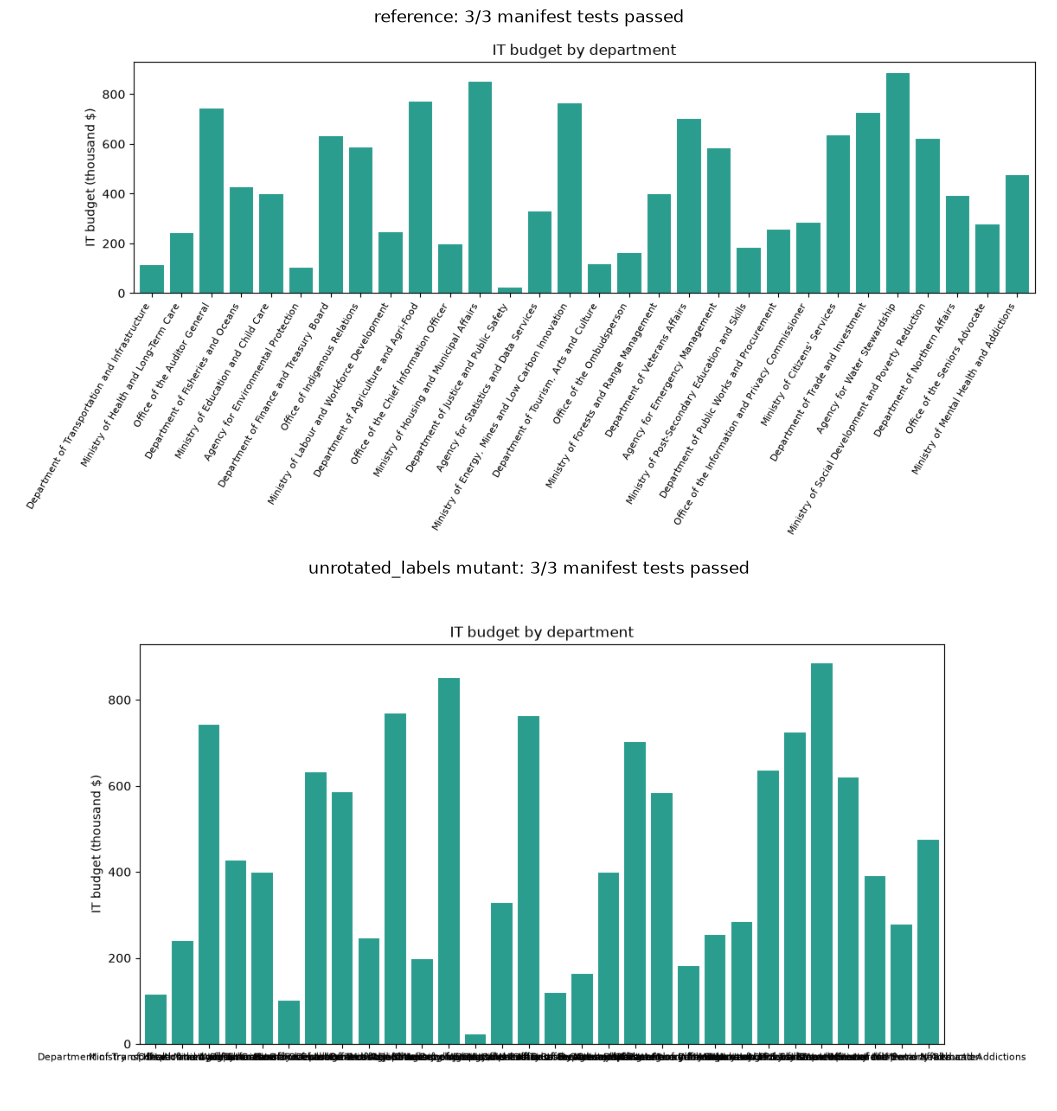

harbor rewards:
  dense-department-budgets     oracle  1.0
  quarterly-revenue-by-region  oracle  1.0
  sensor-daily-median          oracle  1.0
  styled-decay-curves          oracle  1.0
  top-products-unit-share      oracle  1.0
  dense-department-budgets     mutant  1.0  (unrotated_labels, accepted)
  quarterly-revenue-by-region  mutant  0.0  (sum_units, rejected)
submission valid



In [24]:
task_id = "dense-department-budgets"
task_dir = repo / "harbor" / "tasks" / task_id
fig, axes = plt.subplots(2, 1, figsize=(12, 11), layout="constrained")
for ax, (variant, script) in zip(axes, (
        ("reference", task_dir / "solution" / "solve.sh"),
        ("unrotated_labels mutant", task_dir / "mutants" / "unrotated_labels" / "solve.sh"))):
    work, manifest = render(task_id, script)
    _, results = manifest_checks(task_id, manifest)
    passed = sum(outcome == "passed" for outcome in results.values())
    assert passed == len(results) > 0
    ax.imshow(plt.imread(work / "figure.png"))
    ax.set_title(f"{variant}: {passed}/{len(results)} manifest tests passed")
    ax.axis("off")
plt.show()
print((repo / "output" / "check_submission.txt").read_text())

Both versions pass, because the manifest holds the same names, order and values. No test measures rotation, overlap or clipping. The recorded `check-submission` output shows the same result from the real Harbor run: the five reference solutions score 1.0, `sum_units` scores 0.0, and `unrotated_labels` is accepted with 1.0.

> **Takeaway from Harbor.** Exact value checks and a vision judge fail in opposite places. The verifier is exact on numbers and blind to legibility. The judge sees legibility problems and cannot verify a sum over a large input. A real evaluation pipeline should use both, each for the families it can actually decide.

## 9 · Models, cost and budget

### 9.1 · Why hosted APIs and not Modal

The course prescribes `Qwen/Qwen3-VL-30B-A3B-Instruct-FP8` as the judge and three open-weight agents (Qwen2.5-Coder-3B, Ministral-3-14B, GLM-4.7-Flash), each served by the student on Modal GPUs. We chose hosted APIs for three reasons.

1. **Focus.** The assignment is about evaluation design and agent behaviour. Serving four models would have been mostly a deployment exercise. We did that exercise in Assignment 3, hosting and training an open-weight Qwen model on Modal H100s.
2. **Budget.** We set a $10 cap on model calls for this assignment before starting. Pay-per-token APIs fit that cap, and idle GPUs would not.
3. **Variety.** Agents from three providers, all driven through one loop, are a more interesting comparison than three models on one server.

The cost of this choice is comparability. GPT-6.1 Terra is a much stronger judge than a 30B open model, so our MCCs say nothing about what the same validator would score with the course's judge.

| Role | Model | Provider and API | Settings |
| --- | --- | --- | --- |
| Agent A | `deepseek-flash` | DeepSeek, Responses (stateless) | Course limits from §5 |
| Agent B | `gpt-5.6-luna` | OpenAI, Responses | Course limits from §5 |
| Agent C | `glm-5.3-flash` | Z.ai, Chat Completions | Course limits from §5 |
| Judge | `gpt-6.1-terra` | OpenAI, Chat Completions with images | Temperature 0, `reasoning_effort=none`, flex tier, strict JSON schema |

The judge settings were chosen for a batch job. Temperature 0 reduces variation but does not remove it (§4.3). Turning reasoning off keeps each call cheaper and faster. The flex tier costs half the standard price in exchange for slower responses, which a batch of a few hundred calls does not mind.

### 9.2 · What the agents used

In [25]:
per_agent = run_table.groupby(["agent", "model"])[["model calls", "input tokens", "output tokens", "seconds"]].sum()
display(per_agent)
totals = run_table[["model calls", "input tokens", "output tokens"]].sum()
print(f"All 15 runs: {totals['model calls']} model calls, {totals['input tokens']:,} input and "
      f"{totals['output tokens']:,} output tokens, {run_table['seconds'].sum() / 60:.1f} minutes")

,,model calls,input tokens,output tokens,seconds
agent,model,,,,
deepseek,deepseek-flash,24,73508,11725,118.6
glm,glm-5.3-flash,20,35283,3199,127.1
luna,gpt-5.6-luna,20,42807,9101,116.3


All 15 runs: 64 model calls, 151,598 input and 24,025 output tokens, 6.0 minutes


DeepSeek took the most steps and used the most tokens, and GLM used the fewest. The working notes put the cost of all 15 runs together at less than one dollar.

### 9.3 · What the judge cost

When `VALIDATOR_USAGE_LOG` is set, `validator/model.py` appends each judge call's token usage to a log file (`output/judge_usage.jsonl`, kept out of Git), and `scripts/judge_cost.py` turns that log into dollars at Terra's rates: $1 per million input tokens, $0.05 per million cached, $5 per million output, halved for the flex tier. The working notes in `docs/report-notes.md` recorded the total after each stage:

| After | Judge spend so far |
| --- | --- |
| Baseline on the 110 seed runs (402 calls, about 3.34M prompt tokens) | about $1.71 |
| Two Part 2 passes on the seeds and one pass on the authored runs | about $2.66 |
| Part 4a and Part 4b on both sets | $4.41 |
| Final validator on both sets | **$4.84** |

The baseline was the most expensive pass, because it asks up to four questions per run. The next cell counts the calls each validator makes on the seed set.

In [26]:
baseline_stops = sum("execution_failure" in baseline[run_id] for run_id in seed_runs)
baseline_calls = len(seed_runs) + 3 * (len(seed_runs) - baseline_stops)
final_calls = 2 * sum(not failed for failed in gate.values())
print(f"Baseline: 1 execution question per run + 3 more for the {len(seed_runs) - baseline_stops} runs it "
      f"did not stop at = {baseline_calls} calls (402 were logged, including retries)")
print(f"Final:    no call for the {sum(gate.values())} runs without a figure + 2 calls for each of the other "
      f"{sum(not failed for failed in gate.values())} = {final_calls} calls")

Baseline: 1 execution question per run + 3 more for the 97 runs it did not stop at = 401 calls (402 were logged, including retries)
Final:    no call for the 12 runs without a figure + 2 calls for each of the other 98 = 196 calls


The final validator makes half as many calls as the baseline, and it never pays to ask about a run that has no figure.

> **Takeaway on cost.** Logging the usage of every call from the first run made the budget a number we could check before each decision, not a surprise at the end. Every pass in this project, including the experiments we discarded, cost $4.84 for the judge and less than $1 for the agents, against a $10 cap.

## 10 · Lessons, limitations and what we would do next

### What carries over to other work

1. **Decide with code whatever code can decide.** The file check turned the noisiest family into an exact one and removed calls at the same time.
2. **Ask the model for structure and derive the verdict.** A checklist tagged `data`, `design` or `legibility` can be inspected, tested with scripted replies and corrected by changing a definition. A free-form yes/no cannot.
3. **Know the noise before claiming a gain.** Two identical passes differed by 0.01 macro-MCC, so smaller differences were not reported as improvements.
4. **Keep secrets and untrusted code in different processes.** The host holds the keys and calls the models. The container runs the commands and holds no keys.
5. **Use exact checkers and model judges together.** Harbor caught the wrong sum the judge could not see. The judge can see the unreadable labels Harbor accepted.
6. **Ship the version the evidence supports.** The overlay inventory fixed the cases it was built for and was still switched off, with its measurements kept.
7. **Build the thinnest end-to-end version early.** Three days of offline infrastructure produced no chart. One evening on the real data produced every part.

### What the results do not show

- **Different models.** Every number uses GPT-6.1 Terra as the judge and three hosted agents. None of it is comparable with course scores. The Part 4b calibration relies on a judgment a 30B judge may not make reliably.
- **No held-out set.** The 110 seed runs are the public set, and we designed the changes by reading their disagreements. Labels were used only for scoring, but the scores are still likely optimistic.
- **A thin authored set.** The 15 authored runs have positives in one family only, so their macro-MCC cannot exceed 0.25.
- **One pass per configuration,** with about ±0.01 macro-MCC of run-to-run noise.
- **Labels for the authored runs** were drafted by an AI assistant from replays and answer keys, and reviewed by one person.

### What we would try next

1. A "visible in the figure" rule for `wrong_data`, so the judge stops reporting data errors it inferred from the code but cannot see in the chart (seed runs `068`, `086`, `161`).
2. Deterministic summaries of large inputs, such as row counts and per-column totals, so the judge can check aggregates.
3. Re-running the agent's final script under the `savefig` hook inside a sandbox, as we did for labelling, to give the judge the exact plotted values. This was the strongest signal we found, but it runs untrusted code at grading time and needs a sandbox the grader may not have.

### The project in two minutes

We reproduced a CMU agent-evaluation assignment with our own models and sandbox. The task is to build a validator that tells which kinds of mistake an AI agent's chart contains. The starter version asked a vision model four yes/no questions and confused crashes with figures and design errors with data errors (macro-MCC 0.52). We decided execution from the file and asked the model for a tagged requirement checklist plus a separate readability check, which raised macro-MCC to 0.87 and cut false `wrong_data` reports from 46 to 9. We wrote five tasks aimed at the validator's blind spots, ran three agents from three providers in a network-less Docker sandbox, labelled the 15 runs and packaged deterministic verifiers with mutant solutions. The verifiers proved exact on numbers and blind to legibility. One readability idea worked on our tasks but hurt the larger seed set, so we measured it and turned it off. The whole project cost under $6 in API calls.

## 11 · Run the repository's offline checks

The repository pins its dependencies in `uv.lock`, including the Assignment 1 sandbox runtime as a Git dependency. `uv sync` builds that environment next to the notebook kernel. The first run downloads the packages and can take a few minutes.

The checks run the validator's offline unit tests, validate the authored task descriptors and labels, and re-score the final predictions through the command-line workflow. None of them calls a model.

In [27]:
def in_repo(*command, **options):
    return subprocess.run(["uv", "run", "--locked", "--no-sync", *command], cwd=repo, check=True, **options)


subprocess.run(["uv", "sync", "--locked", "--python", "3.12", "--quiet"], cwd=repo, check=True)
in_repo("python", "scripts/offline_preflight.py")
in_repo("python", "-m", "unittest", "discover", "-s", "tests", "-p", "test_validator_*_offline.py")
in_repo("python", "-m", "unittest", "discover", "-s", "tests", "-p", "test_sandbox_generate_offline.py")
in_repo("python", "-m", "workflow", "validate-tasks")
in_repo("python", "-m", "workflow", "validate-labels")
in_repo("python", "-m", "workflow", "score", "--labels", "seed_labels.json",
        "--predictions", "output/final_seed_predictions.json")
in_repo("python", "-m", "workflow", "score", "--predictions", "output/authored_predictions.json")

{
  "runs": 110,
  "figures": 98,
  "labeled_runs": 110,
  "acceptable": 16,
  "families": {
    "execution_failure": 12,
    "hard_to_read": 39,
    "wrong_chart": 71,
    "wrong_data": 25
  }
}
Offline preflight PASSED. No model or cloud infrastructure was called.


..........................

..........usage: python3 -m unittest [-h] [--live] [--confirm-one-request]
python3 -m unittest: error: live mode requires both --live and --confirm-one-request
usage: python3 -m unittest [-h] [--live] [--confirm-one-request]
python3 -m unittest: error: live mode requires both --live and --confirm-one-request
....
----------------------------------------------------------------------
Ran 40 tests in 0.352s

OK


.

..

..
----------------------------------------------------------------------
Ran 5 tests in 2.811s

OK


valid: 5 task descriptor(s)


valid: 15 human-reviewed label(s)


execution_failure    MCC=1.0000  TP=12 TN=98 FP=0 FN=0  support(+/-)=12/98
wrong_data           MCC=0.7093  TP=22 TN=64 FP=9 FN=3  support(+/-)=25/73
wrong_chart          MCC=0.9512  TP=69 TN=27 FP=0 FN=2  support(+/-)=71/27
hard_to_read         MCC=0.8297  TP=33 TN=57 FP=2 FN=6  support(+/-)=39/59
macro_mcc            0.8726


execution_failure    MCC=0.0000  TP=0 TN=15 FP=0 FN=0  support(+/-)=0/15
wrong_data           MCC=0.0000  TP=0 TN=15 FP=0 FN=0  support(+/-)=0/15
wrong_chart          MCC=0.0000  TP=0 TN=15 FP=0 FN=0  support(+/-)=0/15
hard_to_read         MCC=0.5547  TP=2 TN=10 FP=0 FN=3  support(+/-)=5/10
macro_mcc            0.1387


CompletedProcess(args=['uv', 'run', '--locked', '--no-sync', 'python', '-m', 'workflow', 'score', '--predictions', 'output/authored_predictions.json'], returncode=0)

The last command prints an insufficient-support warning for three families. That is the scorer's convention from §6 for a family with no positive labels. Lines that say `live mode requires` come from tests that check a live request is refused without its confirmation flags.

## 12 · Optional live judge call

This cell sends one seed run to the hosted judge with the settings of the recorded experiment: `gpt-6.1-terra` through the OpenAI Chat Completions API, reasoning effort `none`, temperature 0 and the flex service tier. A run with a valid figure costs two requests that each include the image, billed to your OpenAI account. Model names and tiers depend on what your account offers when you run it.

Add `OPENAI_API_KEY` under the key icon in Colab's left sidebar and give this notebook access. Run §11 first, because the call uses that `uv` environment. Then set `RUN_LIVE_JUDGE = True`. The judge is a model, so a rerun can differ from the committed prediction.

In [28]:
RUN_LIVE_JUDGE = False
LIVE_RUN_ID = "021"

if RUN_LIVE_JUDGE:
    try:
        from google.colab import userdata

        api_key = userdata.get("OPENAI_API_KEY")
    except ImportError:
        api_key = os.environ.get("OPENAI_API_KEY")
    assert api_key, "Set OPENAI_API_KEY as a Colab secret or an environment variable."

    live = Path(tempfile.mkdtemp(prefix="live_judge_"))
    shutil.copytree(repo / "artifacts" / LIVE_RUN_ID, live / "artifacts" / LIVE_RUN_ID)
    judge_environment = dict(
        os.environ,
        OPENAI_API_KEY=api_key,
        VALIDATOR_BASE_URL="https://api.openai.com/v1",
        VALIDATOR_MODEL="gpt-6.1-terra",
        VALIDATOR_REASONING_EFFORT="none",
        VALIDATOR_SERVICE_TIER="flex",
    )
    judge_environment.pop("VALIDATOR_API_KEY", None)
    in_repo("python", "-m", "validator.runner",
            "--artifacts", str(live / "artifacts"), "--artifact-root", str(repo),
            "--out", str(live / "predictions.json"), env=judge_environment)

    live_prediction = families_by_run(live / "predictions.json", "predictions")[LIVE_RUN_ID]
    for name, verdict in (("Live judge", live_prediction), ("Committed final", final[LIVE_RUN_ID]),
                          ("Human label", seed_labels[LIVE_RUN_ID])):
        print(f"{name:16s}", sorted(verdict) or "acceptable")
    for family, evidence in live_prediction.items():
        print(f"\n{family}: {evidence}")
else:
    print("To call the hosted judge, add an OPENAI_API_KEY secret and set RUN_LIVE_JUDGE = True.")

To call the hosted judge, add an OPENAI_API_KEY secret and set RUN_LIVE_JUDGE = True.


## 13 · Docker lab in Codespaces

Agent generation and the real Harbor runs need Docker, which a Colab runtime does not provide. Use a Codespace on the repository, or any machine with Docker, Python 3.12 and `uv`. The commands run from the repository root. Model calls are billed by each provider. The [README](https://github.com/xqzr2000/cmu-11-768-assignment-2/blob/main/README.md) has the full reproduction notes and describes the sandbox boundary.

| Step | Entry point | What runs where |
| --- | --- | --- |
| Generate agent runs | `workflow/sandbox_generate.py` | The host holds the API keys and calls the model. Each run gets a fresh container with networking off that executes the agent's bash commands. Only `figure.png` is copied back |
| Judge the runs | `validator/runner.py` | The host sends the task, transcript, inputs and figure to the hosted judge |
| Score | `workflow score` | Offline comparison with human labels |
| Harbor oracles and mutants | `workflow check-submission` | Each packaged task builds its own image and runs its verifier with no network |

### 13.1 · Generate one agent run in the sandbox

Set `DEEPSEEK_API_KEY`, `OPENAI_API_KEY` and `ZAI_API_KEY` as Codespaces secrets or in an ignored `.env` file. Build the plotting image once. Write the probe to a new directory so the 15 committed runs and their labels stay as they are.

```bash
uv sync --locked
docker build -t hw2-chart:1 sandbox/

uv run python -m workflow.sandbox_generate \
  --only styled-decay-curves --models glm --artifacts runs_probe
```

The agent keys are `deepseek`, `luna` and `glm`. A run stops after 20 model steps, 120 seconds per command, or 15 minutes in total. Check `runs_probe/styled-decay-curves__glm/` for `result.json` and `figure.png`. Leave out `--only` and `--models` to run every task with every agent.

### 13.2 · Judge and score your runs

For the Terra judge, set `VALIDATOR_BASE_URL=https://api.openai.com/v1`, `VALIDATOR_MODEL=gpt-6.1-terra`, `VALIDATOR_REASONING_EFFORT=none` and `VALIDATOR_SERVICE_TIER=flex` in `.env`, and leave `VALIDATOR_API_KEY` unset so the client uses `OPENAI_API_KEY`. Set `VALIDATOR_USAGE_LOG=output/judge_usage.jsonl` to log token usage for `scripts/judge_cost.py`. Write predictions to new files so the committed ones stay intact.

```bash
uv run python -m validator.runner --artifacts runs_probe --out output/my_probe_predictions.json

uv run python -m validator.runner --artifacts artifacts \
  --out output/my_seed_predictions.json --workers 4
uv run python -m workflow score --labels seed_labels.json \
  --predictions output/my_seed_predictions.json
uv run python scripts/disagreements.py output/my_seed_predictions.json
uv run python scripts/judge_cost.py --flex
```

A new agent run has no human label yet. Look at its figure and write the label before you read the validator's prediction, then add it to a label file and score. If the runner stops with failed runs, fix the cause and repeat the command with `--resume` to judge only the missing ones.

### 13.3 · Run the Harbor oracles and mutants

```bash
uv run harbor run -p harbor/tasks/quarterly-revenue-by-region -a oracle \
  --job-name quarterly-revenue-by-region-oracle

uv run python -m workflow check-submission
```

The first command runs one reference solution through its verifier and should report a reward of 1.0. `check-submission` validates the whole submission and reruns all five oracles and both mutants. Compare its output with [`output/check_submission.txt`](https://github.com/xqzr2000/cmu-11-768-assignment-2/blob/main/output/check_submission.txt).

### 13.4 · Problems we hit and how the repository handles them

| What we saw | How we checked it | What the repository does |
| --- | --- | --- |
| The baseline reported crashes for runs that had saved a figure, and accepted runs with none | Compared `execution_failure` predictions with whether `figure.png` exists | `judge_execution` decides from the file and makes no model call |
| 46 `wrong_data` false positives on runs with a design error | Read the baseline's evidence next to the human label | One checklist call tags each requirement `data`, `design` or `legibility` |
| Two passes of the same validator differed by about 0.01 macro-MCC at temperature 0 | Scored both Part 2 passes | Differences of that size are treated as noise |
| The overlay inventory fixed the authored misses and added seed false positives | Scored the seed and authored sets after each change | `OVERLAY_INVENTORY = False` in the final validator |
| The `unrotated_labels` mutant scored 1.0 in Harbor | Looked at the figure the verifier accepted | Recorded as a verifier blind spot in the report |
| The free `glm-4.7-flash` endpoint was rate-limited | One compatibility probe with no retries | Agent C uses the paid `glm-5.3-flash`; the runner retries rate limits with backoff |
| Newer OpenAI models reject `max_tokens` or a non-default `temperature` | The API returns a 400 that names the parameter | `validator/model.py` renames or drops the parameter and retries |

Read the [final report](https://github.com/xqzr2000/cmu-11-768-assignment-2/blob/main/report.pdf) for the full error analysis, the [iteration notes](https://github.com/xqzr2000/cmu-11-768-assignment-2/blob/main/docs/report-notes.md) for the measurements behind each decision, and the [learning log](https://github.com/xqzr2000/cmu-11-768-assignment-2/blob/main/docs/Learning-Progress.md) for the session-by-session history of Phase A.